# Exam Project 3: Customer Lifetime Value (CLTV) Analysis — Olist E-Commerce
**Course:** AI for Communication and Marketing — B.Sc. in Artificial Intelligence  
**Dataset:** Brazilian E-Commerce Public Dataset by Olist (Kaggle)  
**Goal:** Predict CLTV using probabilistic (BG/NBD + Gamma-Gamma) and ML (XGBoost) models

## Setup & Imports

In [1]:
# ── Install required packages (run once) ───────────────────────────────────
import subprocess, sys
pkgs = ['lifetimes', 'xgboost', 'scikit-learn', 'matplotlib', 'seaborn']
for pkg in pkgs:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', pkg, '-q'])
print('All packages installed ✓')

All packages installed ✓


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from lifetimes import BetaGeoFitter, GammaGammaFitter
from lifetimes.utils import calibration_and_holdout_data
from lifetimes.plotting import (
    plot_frequency_recency_matrix,
    plot_probability_alive_matrix,
    plot_period_transactions
)

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error
import xgboost as xgb

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 120
SEED = 42

# ── Path to data files ──────────────────────────────────
DATA_PATH = ''
print('Libraries loaded ✓')

Libraries loaded ✓


---
## Task A — Data Audit & Cleaning

### A.1 — Load raw tables

In [3]:
customers = pd.read_csv(DATA_PATH + 'olist_customers_dataset.csv')
orders    = pd.read_csv(DATA_PATH + 'olist_orders_dataset.csv',
                        parse_dates=['order_purchase_timestamp',
                                     'order_approved_at',
                                     'order_delivered_customer_date',
                                     'order_estimated_delivery_date'])
payments  = pd.read_csv(DATA_PATH + 'olist_order_payments_dataset.csv')
items     = pd.read_csv(DATA_PATH + 'olist_order_items_dataset.csv',
                        parse_dates=['shipping_limit_date'])

print(f'customers : {customers.shape}')
print(f'orders    : {orders.shape}')
print(f'payments  : {payments.shape}')
print(f'items     : {items.shape}')

customers : (99441, 5)
orders    : (99441, 8)
payments  : (103886, 5)
items     : (112650, 7)


### A.2 — Data Audit: missing values & duplicates

In [4]:
def audit_df(df, name):
    print(f'\n{'='*50}')
    print(f'  TABLE: {name}')
    print(f'{'='*50}')
    print(f'  Shape           : {df.shape}')
    print(f'  Duplicate rows  : {df.duplicated().sum()}')
    nulls = df.isnull().sum()
    nulls = nulls[nulls > 0]
    if len(nulls):
        print(f'  Missing values  :\n{nulls.to_string()}')
    else:
        print(f'  Missing values  : None')

for df, name in [(customers, 'customers'), (orders, 'orders'),
                 (payments, 'payments'), (items, 'items')]:
    audit_df(df, name)


  TABLE: customers
  Shape           : (99441, 5)
  Duplicate rows  : 0
  Missing values  : None

  TABLE: orders
  Shape           : (99441, 8)
  Duplicate rows  : 0
  Missing values  :
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965

  TABLE: payments
  Shape           : (103886, 5)
  Duplicate rows  : 0
  Missing values  : None

  TABLE: items
  Shape           : (112650, 7)
  Duplicate rows  : 0
  Missing values  : None


**Audit Results**

The dataset is in excellent condition—no duplicates in any of the four tables. The only missing values ​​are in the `orders` table in the delivery date columns (`order_delivered_customer_date`: 2,965 null, `order_delivered_carrier_date`: 1,783 null, `order_approved_at`: 160 null).

These columns are not used in the RFM calculation for a specific conceptual reason: the RFM model (and the probabilistic BG/NBD models that will be used later) measures the customer's purchasing behavior, that is, when they decide to buy, not when the goods arrive. The relevant date is therefore the `order_purchase_timestamp` (the time of the purchase decision), not the logistics dates. Furthermore, `order_purchase_timestamp` is 100% complete (no nulls), eliminating any need for imputation.

### A.3 — Data Cleaning pipeline

In [5]:
# Raw dataset
orders

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26
...,...,...,...,...,...,...,...,...
99436,9c5dedf39a927c1b2549525ed64a053c,39bd1228ee8140590ac3aca26f2dfe00,delivered,2017-03-09 09:54:05,2017-03-09 09:54:05,2017-03-10 11:18:03,2017-03-17 15:08:01,2017-03-28
99437,63943bddc261676b46f01ca7ac2f7bd8,1fca14ff2861355f6e5f14306ff977a7,delivered,2018-02-06 12:58:58,2018-02-06 13:10:37,2018-02-07 23:22:42,2018-02-28 17:37:56,2018-03-02
99438,83c1379a015df1e13d02aae0204711ab,1aa71eb042121263aafbe80c1b562c9c,delivered,2017-08-27 14:46:43,2017-08-27 15:04:16,2017-08-28 20:52:26,2017-09-21 11:24:17,2017-09-27
99439,11c177c8e97725db2631073c19f07b62,b331b74b18dc79bcdf6532d51e1637c1,delivered,2018-01-08 21:28:27,2018-01-08 21:36:21,2018-01-12 15:35:03,2018-01-25 23:32:54,2018-02-15


#### Core cleaning pipeline

**Note on Step 1 — Keeping only `delivered` orders**

We retain only the **96,478 orders with the `delivered`** status (~97% of the total), discarding `shipped`, `cancelled`, `unavailable`, etc. The rationale is that only delivered orders represent completed transactions with actual cash receipts, which is essential for reliably estimating monetary value. Canceled or unfulfilled orders would alter both the Monetary Value and Frequency of the RFM model.

In [6]:
# ── Step 1: keep only delivered orders (valid, completed transactions) ─────
print(f'Order statuses before filtering:\n{orders["order_status"].value_counts()}')

orders_clean = orders[orders['order_status'] == 'delivered'].copy()
print(f'\nRows after keeping only "delivered": {len(orders_clean):,}')

# ── Step 2: drop rows with missing purchase timestamp (can't compute RFM) ──
orders_clean = orders_clean.dropna(subset=['order_purchase_timestamp'])

Order statuses before filtering:
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

Rows after keeping only "delivered": 96,478


**Note on Step 3 — Aggregating Payments by Order:**

In the Olist dataset, a single order can be split across multiple rows in the payments table when the customer pays with multiple methods or in installments ( `payment_sequential` > 1). To obtain the actual financial value of each order, we add all rows with the same  `order_id`. Using the sum (rather than keeping the row with  `payment_sequential` == 1) ensures that the entire amount paid is correctly attributed to that order.

In [7]:
# ── Step 3: aggregate payments per order (handle split/installment payments)
# Sum payment_value across all payment_sequential entries for the same order
payments_agg = (payments
                .groupby('order_id', as_index=False)['payment_value']
                .sum()
                .rename(columns={'payment_value': 'order_value'}))

**Note on Step 4 — Using `customer_unique_id` instead of `customer_id`:**

In the Olist dataset, `customer_id` identifies the *order session*, not the physical customer: the same customer can have a different `customer_id` for each order placed. `customer_unique_id` is the customer's stable identifier over time. Using `customer_id` would artificially produce a frequency of 0 for everyone (each customer would appear to have purchased only once), making it impossible to calculate RFM metrics and train BTYD models.

In [8]:
# ── Step 4: merge orders ← customers ← payments ────────────────────────────
df = (orders_clean
      .merge(customers[['customer_id', 'customer_unique_id']], on='customer_id', how='left')
      .merge(payments_agg, on='order_id', how='left'))

In [9]:
print(f'\nMerged dataset shape: {df.shape}')
print(f'Null order_value: {df["order_value"].isnull().sum()}')


Merged dataset shape: (96478, 10)
Null order_value: 1


In [10]:
df

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,order_value
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,7c396fd4830fd04220f754e42b4e5bff,38.71
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,af07308b275d755c9edb36a90c618231,141.46
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,3a653a41f6f9fc3d2a113cf8398680e8,179.12
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,7c142cf63193a1473d2e66489a9ae977,72.20
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,72632f0f9dd73dfee390c9b22eb56dd6,28.62
...,...,...,...,...,...,...,...,...,...,...
96473,9c5dedf39a927c1b2549525ed64a053c,39bd1228ee8140590ac3aca26f2dfe00,delivered,2017-03-09 09:54:05,2017-03-09 09:54:05,2017-03-10 11:18:03,2017-03-17 15:08:01,2017-03-28,6359f309b166b0196dbf7ad2ac62bb5a,85.08
96474,63943bddc261676b46f01ca7ac2f7bd8,1fca14ff2861355f6e5f14306ff977a7,delivered,2018-02-06 12:58:58,2018-02-06 13:10:37,2018-02-07 23:22:42,2018-02-28 17:37:56,2018-03-02,da62f9e57a76d978d02ab5362c509660,195.00
96475,83c1379a015df1e13d02aae0204711ab,1aa71eb042121263aafbe80c1b562c9c,delivered,2017-08-27 14:46:43,2017-08-27 15:04:16,2017-08-28 20:52:26,2017-09-21 11:24:17,2017-09-27,737520a9aad80b3fbbdad19b66b37b30,271.01
96476,11c177c8e97725db2631073c19f07b62,b331b74b18dc79bcdf6532d51e1637c1,delivered,2018-01-08 21:28:27,2018-01-08 21:36:21,2018-01-12 15:35:03,2018-01-25 23:32:54,2018-02-15,5097a5312c8b157bb7be58ae360ef43c,441.16


**Remaining null in `order_value`:**

After the merge, one row remains with a null `order_value`. This is a "delivered" order present in the `orders` table but not in `payments`, likely an anomalous entry or an order without a recorded transaction. Since it represents less than 0.001% of the data and is not interpretable for CLTV purposes, it will be removed during feature engineering.

#### Outlier analysis: `order_value`

Percentiles order_value:
    50° pct: R$     105.28
    75° pct: R$     176.33
    90° pct: R$     305.97
    95° pct: R$     446.31
    99° pct: R$    1052.39
    99° pct: R$    1416.85
   100° pct: R$   13664.08


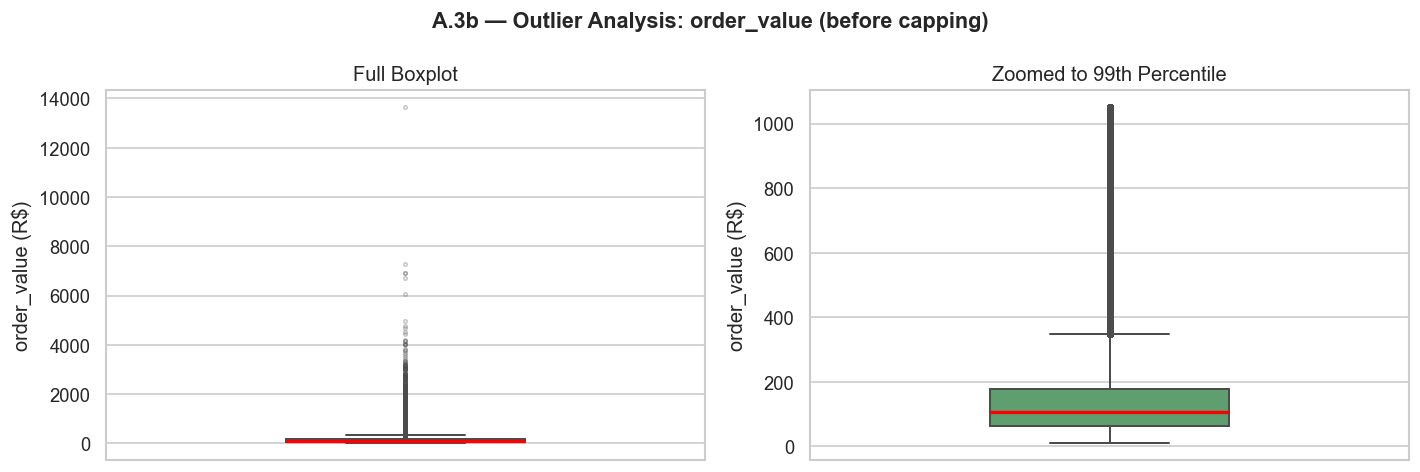

In [11]:
# Boxplot order_value: distribution BEFORE capping 
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
fig.suptitle('A.3b — Outlier Analysis: order_value (before capping)', fontsize=13, fontweight='bold')

# Complete boxplot
sns.boxplot(y=df['order_value'], ax=axes[0],
            color='#4C72B0', width=0.4, linewidth=1.2,
            flierprops=dict(marker='o', markersize=2, alpha=0.3, color='#C44E52'),
            medianprops=dict(color='red', linewidth=2))
axes[0].set_title('Full Boxplot')
axes[0].set_ylabel('order_value (R$)')
axes[0].set_xlabel('')

# Zoomed boxplot at 99° percentile
p99 = df['order_value'].quantile(0.99)
sns.boxplot(y=df['order_value'].clip(upper=p99), ax=axes[1],
            color='#55A868', width=0.4, linewidth=1.2,
            flierprops=dict(marker='o', markersize=3, alpha=0.4, color='#C44E52'),
            medianprops=dict(color='red', linewidth=2))
axes[1].set_title('Zoomed to 99th Percentile')
axes[1].set_ylabel('order_value (R$)')
axes[1].set_xlabel('')

# Percentiles table
pcts = df['order_value'].quantile([0.5, 0.75, 0.9, 0.95, 0.99, 0.995, 1.0])
print('Percentiles order_value:')
for p, v in pcts.items():
    print(f'  {int(p*100):>4}° pct: R$ {v:>10.2f}')

plt.tight_layout()
plt.savefig('boxplot_order_value.png', bbox_inches='tight')
plt.show()


**Outlier Analysis — `order_value`:**

The boxplot reveals a **strongly right-skewed** distribution with a long tail of high-value orders. The 95th percentile is already well above the median, and the values ​​at the 99.5th percentile (the chosen capping threshold) are orders of magnitude higher than the mean. These extreme outliers represent atypical purchases (e.g., luxury appliances, B2B orders) that, if left untreated, would distort the RFM model's **Monetary Value** by artificially inflating the value estimate of a few customers. **Capping at the 99.5th percentile** (rather than eliminating it) preserves these customers in the segmentation but neutralizes the bias on the model parameters.

**Outlier Treatment**

The extreme order values ​​(top 0.5%) are **capped at R$ 1,416.85** instead of being eliminated. This choice is preferable to elimination because:

1. These customers are real and have high segmentation value;

2. Capping preserves the relative ordering among customers without distorting the distributions. The final dataset contains **96,477 transactions** out of **93,357 unique customers**.

In [12]:
# ── Step 5: remove orders with zero or negative value ──────────────────────
df = df[df['order_value'] > 0].copy()
print(f'After removing zero/negative values: {len(df):,} rows')

# ── Step 6: outlier treatment on order_value (cap at 99.5th percentile) ────
cap = df['order_value'].quantile(0.995)
df['order_value'] = df['order_value'].clip(upper=cap)
print(f'Order value cap (99.5th pct): R$ {cap:.2f}')

# ── Step 7: date range overview ─────────────────────────────────────────────
print(f'\nDate range: {df["order_purchase_timestamp"].min().date()} → {df["order_purchase_timestamp"].max().date()}')
print(f'Total unique customers: {df["customer_unique_id"].nunique():,}')
print(f'Total orders           : {len(df):,}')

After removing zero/negative values: 96,477 rows
Order value cap (99.5th pct): R$ 1416.85

Date range: 2016-10-03 → 2018-08-29
Total unique customers: 93,357
Total orders           : 96,477


In [13]:
# Cleaned dataset
df

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,order_value
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,7c396fd4830fd04220f754e42b4e5bff,38.71
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,af07308b275d755c9edb36a90c618231,141.46
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,3a653a41f6f9fc3d2a113cf8398680e8,179.12
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,7c142cf63193a1473d2e66489a9ae977,72.20
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,72632f0f9dd73dfee390c9b22eb56dd6,28.62
...,...,...,...,...,...,...,...,...,...,...
96473,9c5dedf39a927c1b2549525ed64a053c,39bd1228ee8140590ac3aca26f2dfe00,delivered,2017-03-09 09:54:05,2017-03-09 09:54:05,2017-03-10 11:18:03,2017-03-17 15:08:01,2017-03-28,6359f309b166b0196dbf7ad2ac62bb5a,85.08
96474,63943bddc261676b46f01ca7ac2f7bd8,1fca14ff2861355f6e5f14306ff977a7,delivered,2018-02-06 12:58:58,2018-02-06 13:10:37,2018-02-07 23:22:42,2018-02-28 17:37:56,2018-03-02,da62f9e57a76d978d02ab5362c509660,195.00
96475,83c1379a015df1e13d02aae0204711ab,1aa71eb042121263aafbe80c1b562c9c,delivered,2017-08-27 14:46:43,2017-08-27 15:04:16,2017-08-28 20:52:26,2017-09-21 11:24:17,2017-09-27,737520a9aad80b3fbbdad19b66b37b30,271.01
96476,11c177c8e97725db2631073c19f07b62,b331b74b18dc79bcdf6532d51e1637c1,delivered,2018-01-08 21:28:27,2018-01-08 21:36:21,2018-01-12 15:35:03,2018-01-25 23:32:54,2018-02-15,5097a5312c8b157bb7be58ae360ef43c,441.16


---
## Task B — Exploratory Data Analysis & RFM Feature Engineering

### B.1 — Define Calibration / Holdout split

The dataset spans **Sep 2016 → Oct 2018** (~25 months).  
- **Calibration period**: 2016-10-01 → 2018-03-31 (18 months) — used to train models  
- **Holdout period**: 2018-04-01 → 2018-08-31 (5 months) — used to evaluate predictions  

We exclude the first ~month (Sep 2016) due to data sparsity.

In [14]:
CALIB_START  = pd.Timestamp('2016-10-01')
CALIB_END    = pd.Timestamp('2018-03-31')
HOLDOUT_END  = pd.Timestamp('2018-08-31')

df_period = df[(df['order_purchase_timestamp'] >= CALIB_START) &
               (df['order_purchase_timestamp'] <= HOLDOUT_END)].copy()

df_calib   = df_period[df_period['order_purchase_timestamp'] <= CALIB_END].copy()
df_holdout = df_period[(df_period['order_purchase_timestamp'] > CALIB_END) &
                       (df_period['order_purchase_timestamp'] <= HOLDOUT_END)].copy()

print(f'Calibration orders : {len(df_calib):,}  | customers: {df_calib["customer_unique_id"].nunique():,}')
print(f'Holdout orders     : {len(df_holdout):,}  | customers: {df_holdout["customer_unique_id"].nunique():,}')

Calibration orders : 64,157  | customers: 62,144
Holdout orders     : 32,320  | customers: 31,822


**Choice of Calibration/Holdout Split**

The dataset covers ~25 months (Oct 2016 → Aug 2018). We defined:
- **Calibration**: Oct 2016 → Mar 2018 (18 months) → **64,157 orders, 62,144 customers**
- **Holdout**: Apr 2018 → Aug 2018 (5 months) → **32,320 orders, 31,822 customers**

### B.2 — EDA: Purchase frequency, Recency, Spend

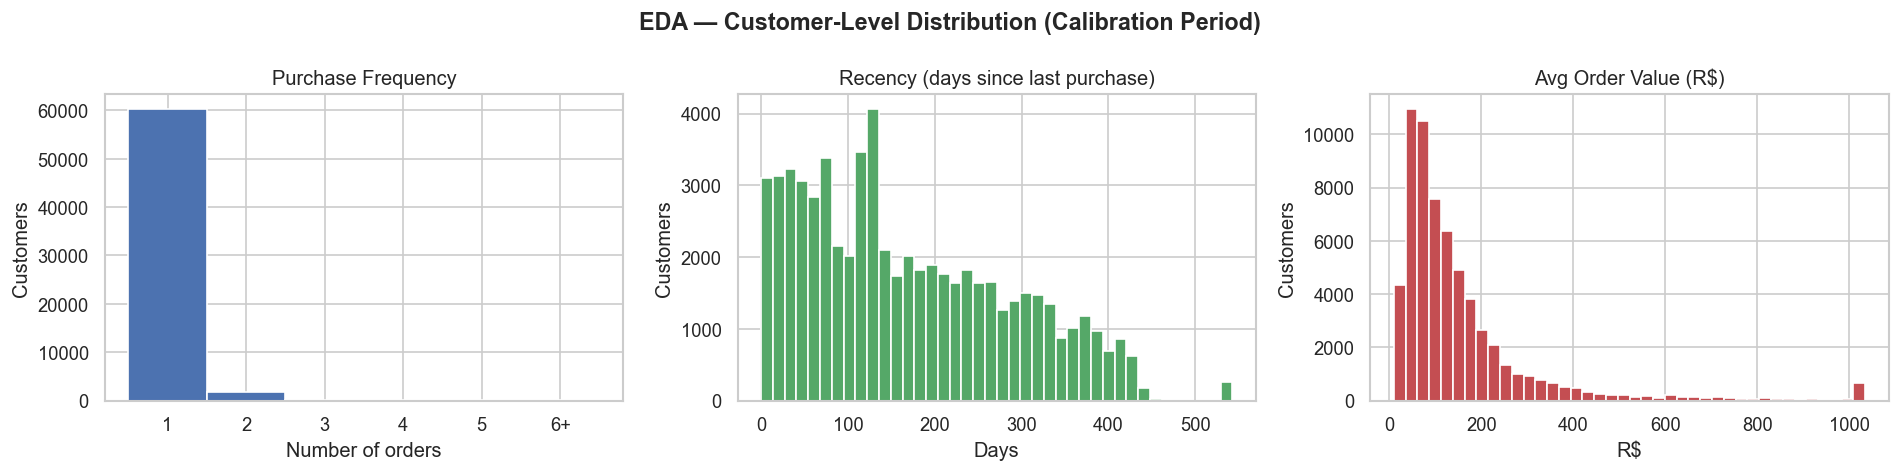

In [15]:
# ── Customer-level aggregation for EDA ─────────────────────────────────────
observation_date = CALIB_END

eda = (df_calib
       .groupby('customer_unique_id')
       .agg(
           frequency = ('order_id', 'count'),
           last_purchase = ('order_purchase_timestamp', 'max'),
           total_spend = ('order_value', 'sum'),
           avg_spend = ('order_value', 'mean')
       )
       .reset_index())

eda['recency_days'] = (observation_date - eda['last_purchase']).dt.days

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
fig.suptitle('EDA — Customer-Level Distribution (Calibration Period)', fontsize=14, fontweight='bold')

# Purchase frequency (cap at 5 for readability)
freq_capped = eda['frequency'].clip(upper=6)
axes[0].hist(freq_capped, bins=range(1, 8), edgecolor='white', color='#4C72B0', align='left')
axes[0].set_title('Purchase Frequency')
axes[0].set_xlabel('Number of orders')
axes[0].set_ylabel('Customers')
axes[0].xaxis.set_major_locator(mticker.MultipleLocator(1))
axes[0].set_xticklabels([str(i) if i < 6 else '6+' for i in range(0, 8)])

# Recency
axes[1].hist(eda['recency_days'], bins=40, edgecolor='white', color='#55A868')
axes[1].set_title('Recency (days since last purchase)')
axes[1].set_xlabel('Days')
axes[1].set_ylabel('Customers')

# Average spend (winsorise at 99th pct for plot)
spend_plot = eda['avg_spend'].clip(upper=eda['avg_spend'].quantile(0.99))
axes[2].hist(spend_plot, bins=40, edgecolor='white', color='#C44E52')
axes[2].set_title('Avg Order Value (R$)')
axes[2].set_xlabel('R$')
axes[2].set_ylabel('Customers')

plt.tight_layout()
plt.savefig('eda_distributions.png', bbox_inches='tight')
plt.show()

**Motivation: Choice of EDA Dimensions**

The three distributions analyzed directly reflect the three components of the RFM model and the probabilistic BG/NBD model:

- **Purchase Frequency:** shows that the vast majority of customers (~97%) placed only one order in the calibration period. This highly skewed distribution is a well-known characteristic of e-commerce and motivates the use of the BG/NBD model, which is specifically designed to handle populations with a high percentage of one-time buyers.

- **Recency (time since last purchase):** provides information on how "active" the customer is compared to the end of the observation period. A uniform distribution indicates that purchases are spread out over time without anomalous concentrations.

- **Average Order Value (Spend):** The strong positive skewness (long right tail) justifies the use of the Gamma-Gamma model, which assumes a Gamma distribution for individual transaction values—a distribution suitable for positive and skewed data.

These three dimensions are also those that maximize the predictive signal for CLTV models without requiring additional data that is not always available (e.g. product categories, acquisition channel).

In [16]:
print(f'\n--- Summary Statistics ---')
print(eda[['frequency','recency_days','avg_spend']].describe().round(2))


--- Summary Statistics ---
       frequency  recency_days  avg_spend
count   62144.00      62144.00   62144.00
mean        1.03        168.20     155.00
std         0.20        118.77     177.28
min         1.00          0.00      10.07
25%         1.00         68.00      61.79
50%         1.00        139.00     104.37
75%         1.00        255.25     175.24
max         9.00        543.00    1416.85


**EDA Insight based on numbers:** The frequency distribution is heavily concentrated around 1 purchase (mean 1.03). The average recency is **168 days** (more than 5 months from the last purchase to the end date), indicating that most customers stopped purchasing early. The average spend is **R$155** with high variance (std 177), indicating a tail of high-value customers. These patterns are typical of low-loyalty e-commerce.

### B.3 — Customer Retention Insight

#### Retention Overview

One-time buyers : 60,323 (97.1%)
Repeat buyers   : 1,821 (2.9%)


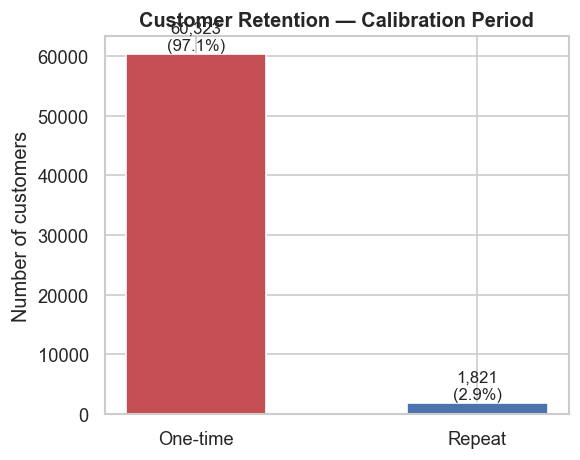

In [17]:
# ── One-time vs repeat buyers ───────────────────────────────────────────────
one_time = (eda['frequency'] == 1).sum()
repeat   = (eda['frequency'] > 1).sum()
total_eda = len(eda)

print(f'One-time buyers : {one_time:,} ({one_time/total_eda:.1%})')
print(f'Repeat buyers   : {repeat:,} ({repeat/total_eda:.1%})')

fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(['One-time', 'Repeat'], [one_time, repeat], color=['#C44E52','#4C72B0'], width=0.5)
ax.set_title('Customer Retention — Calibration Period', fontweight='bold')
ax.set_ylabel('Number of customers')
for bar, val in zip(ax.patches, [one_time, repeat]):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 200,
            f'{val:,}\n({val/total_eda:.1%})', ha='center', va='bottom', fontsize=10)
plt.tight_layout()
plt.savefig('retention_bar.png', bbox_inches='tight')
plt.show()

**Critical retention:** **97.1% of customers made only one purchase** during the calibration period. From the perspective of the BG/NBD model, this situation is manageable: the model is specifically designed to estimate the probability that even customers with only one purchase are still "active" or have permanently churned.

#### Monthly Acquisition Cohort Analysis

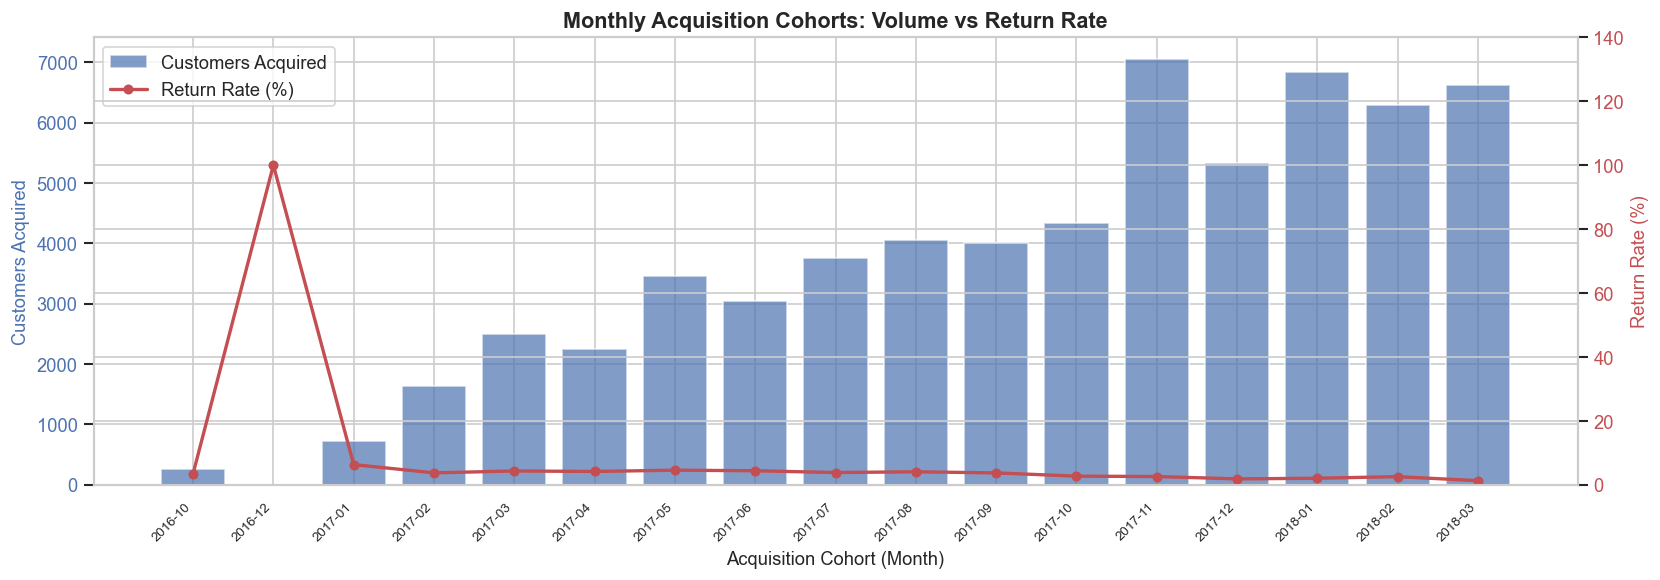

Average return rate across cohorts: 9.1%
Best cohort:  2016-12 (100.0%)
Worst cohort: 2018-03 (1.2%)


In [18]:
# ── Monthly cohort analysis: acquisition month vs return rate ────────────────
# Assign each customer to their acquisition cohort (month of first purchase)
first_purchase = (df_calib
                  .groupby('customer_unique_id')['order_purchase_timestamp']
                  .min()
                  .rename('first_purchase'))

cohort_df = df_calib.merge(first_purchase, on='customer_unique_id')
cohort_df['cohort_month'] = cohort_df['first_purchase'].dt.to_period('M')

# For each cohort: total customers acquired, and how many made a repeat purchase
cohort_stats = (cohort_df
                .groupby('cohort_month')
                .agg(
                    customers_acquired = ('customer_unique_id', 'nunique'),
                    total_orders       = ('order_id', 'nunique')
                ))

cohort_stats['repeat_buyers'] = (
    cohort_df[cohort_df.groupby('customer_unique_id')['order_id']
              .transform('nunique') > 1]
    .groupby('cohort_month')['customer_unique_id']
    .nunique()
).reindex(cohort_stats.index, fill_value=0)

cohort_stats['return_rate'] = (cohort_stats['repeat_buyers'] 
                                / cohort_stats['customers_acquired'] * 100)

# ── Visualisation: dual-axis chart ──────────────────────────────────────────
fig, ax1 = plt.subplots(figsize=(14, 5))

x_labels = cohort_stats.index.astype(str)
x = np.arange(len(x_labels))

# Bars: customers acquired
ax1.bar(x, cohort_stats['customers_acquired'], color='#4C72B0', alpha=0.7, label='Customers Acquired')
ax1.set_xlabel('Acquisition Cohort (Month)', fontsize=11)
ax1.set_ylabel('Customers Acquired', fontsize=11, color='#4C72B0')
ax1.set_xticks(x)
ax1.set_xticklabels(x_labels, rotation=45, ha='right', fontsize=8)
ax1.tick_params(axis='y', labelcolor='#4C72B0')

# Line: return rate
ax2 = ax1.twinx()
ax2.plot(x, cohort_stats['return_rate'], color='#C44E52', marker='o', 
         linewidth=2, markersize=5, label='Return Rate (%)')
ax2.set_ylabel('Return Rate (%)', fontsize=11, color='#C44E52')
ax2.tick_params(axis='y', labelcolor='#C44E52')
ax2.set_ylim(0, cohort_stats['return_rate'].max() * 1.4)

# Combined legend
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left')

ax1.set_title('Monthly Acquisition Cohorts: Volume vs Return Rate', fontweight='bold', fontsize=13)
plt.tight_layout()
plt.savefig('cohort_analysis.png', bbox_inches='tight')
plt.show()

# ── Summary stats ────────────────────────────────────────────────────────────
print(f'Average return rate across cohorts: {cohort_stats["return_rate"].mean():.1f}%')
print(f'Best cohort:  {cohort_stats["return_rate"].idxmax()} ({cohort_stats["return_rate"].max():.1f}%)')
print(f'Worst cohort: {cohort_stats["return_rate"].idxmin()} ({cohort_stats["return_rate"].min():.1f}%)')

**Cohort Analysis — Key Insights**

The dual-axis chart reveals two important dynamics:

- **Acquisition volume** grew significantly over time, peaking in late 2017 and early 2018 — reflecting Olist's marketplace growth. The earlier cohorts (late 2016 – early 2017) are smaller but had more time to generate repeat purchases within the calibration window.

- **Return rate** is consistently low across all cohorts (typically 2–5%), confirming that the one-time buyer problem is structural and not limited to a specific acquisition period. However, the earliest cohorts tend to show slightly higher return rates — this is partly a **maturation effect**: customers acquired earlier had a longer observation window in which to make a repeat purchase.

**Marketing implication:** The uniformly low return rate across cohorts suggests that the current customer journey does not naturally encourage repeat purchases. Any loyalty or retention initiative would need to actively intervene (e.g., post-purchase email sequences, personalised discounts) rather than relying on organic return behaviour. The cohort view also provides a baseline for measuring the incremental impact of future retention campaigns: if a new campaign lifts the return rate of a cohort above the historical 2–5% range, it is demonstrably effective.

### B.4 — RFM Feature Engineering (with T = customer tenure)

**Construction of RFM metrics**

- **Recency (R):** defined as the time (in days or weeks) elapsed since the last purchase compared to the end of the calibration period. In the BG/NBD context, recency relative to the observed customer lifetime is the signal that allows us to distinguish customers who have stopped purchasing from those who purchase with low frequency.

- **Frequency (F):** number of *repeat* purchases (= total number of purchases − 1). BTYD models require excluding the first purchase (which is the entry condition in the dataset, not a behavioral signal). Customers with frequency = 0 are one-time buyers.

- **Monetary Value (M):** calculated as the **average** of the value of individual orders (not the sum). This is a deliberate choice: the Gamma-Gamma model estimates the distribution of the *average value per transaction* for each customer, not the total. Using the sum would introduce a bias toward customers with many purchases, confusing frequency and unit value.

- **T (customer age):** Time (in days/weeks) between the customer's first purchase and the end of the calibration period. It represents the "observed lifetime" that the model uses, along with recency, to estimate the probability that the customer is still active.

**Customers with frequency = 0** are retained in the BG/NBD dataset (which estimates the probability of being still "alive" even for one-time buyers) but **excluded** from the Gamma-Gamma fit, which requires at least two observations to estimate the variability of the individual mean value.

In [19]:
# lifetimes requires the summary_data_from_transaction_data format:
    # frequency = number of REPEAT purchases (first excluded)
    # recency   = time between first and last purchase
    # T         = time between first purchase and observation date
    # monetary_value = average spend on repeat purchases

from lifetimes.utils import summary_data_from_transaction_data

rfm_calib = summary_data_from_transaction_data(
    transactions        = df_calib,
    customer_id_col     = 'customer_unique_id',
    datetime_col        = 'order_purchase_timestamp',
    monetary_value_col  = 'order_value',
    observation_period_end = CALIB_END,
    freq                = 'D'
)

print('RFM table shape:', rfm_calib.shape)
print(rfm_calib.head(10).round(2))

RFM table shape: (62144, 4)
                                  frequency  recency      T  monetary_value
customer_unique_id                                                         
0000f46a3911fa3c0805444483337064        0.0      0.0  386.0             0.0
0000f6ccb0745a6a4b88665a16c9f078        0.0      0.0  170.0             0.0
0004aac84e0df4da2b147fca70cf8255        0.0      0.0  137.0             0.0
00053a61a98854899e70ed204dd4bafe        0.0      0.0   31.0             0.0
0005e1862207bf6ccc02e4228effd9a0        0.0      0.0  392.0             0.0
0005ef4cd20d2893f0d9fbd94d3c0d97        0.0      0.0   19.0             0.0
0006fdc98a402fceb4eb0ee528f6a8d4        0.0      0.0  256.0             0.0
00082cbe03e478190aadbea78542e933        0.0      0.0  132.0             0.0
00090324bbad0e9342388303bb71ba0a        0.0      0.0    7.0             0.0
000a5ad9c4601d2bbdd9ed765d5213b3        0.0      0.0  232.0             0.0


In [20]:
# ── RFM descriptive stats ───────────────────────────────────────────────────
print(rfm_calib.describe().round(2))

# ── Check BG/NBD assumption: frequency and monetary_value should be weakly correlated (Gamma-Gamma assumption) ─────────────────────────────
repeat_buyers = rfm_calib[rfm_calib['frequency'] > 0]
corr = repeat_buyers['frequency'].corr(repeat_buyers['monetary_value'])
print(f'\nCorrelation between frequency and monetary_value (repeat buyers): {corr:.4f}')
print('→ Should be near 0 for Gamma-Gamma model validity')

       frequency   recency         T  monetary_value
count   62144.00  62144.00  62144.00        62144.00
mean        0.02      1.75    170.95            2.67
std         0.16     17.94    119.19           28.14
min         0.00      0.00      1.00            0.00
25%         0.00      0.00     71.00            0.00
50%         0.00      0.00    142.00            0.00
75%         0.00      0.00    259.00            0.00
max         7.00    524.00    544.00         1416.85

Correlation between frequency and monetary_value (repeat buyers): 0.0032
→ Should be near 0 for Gamma-Gamma model validity



Percentiles RFM metrics:
                        frequency    recency          T  monetary_value
   50° percentile:        0.0        0.0      142.0            0.00
   75° percentile:        0.0        0.0      259.0            0.00
   90° percentile:        0.0        0.0      348.0            0.00
   95° percentile:        0.0        0.0      389.0            0.00
   99° percentile:        1.0       53.0      430.0           96.80
  100° percentile:        7.0      524.0      544.0         1416.85


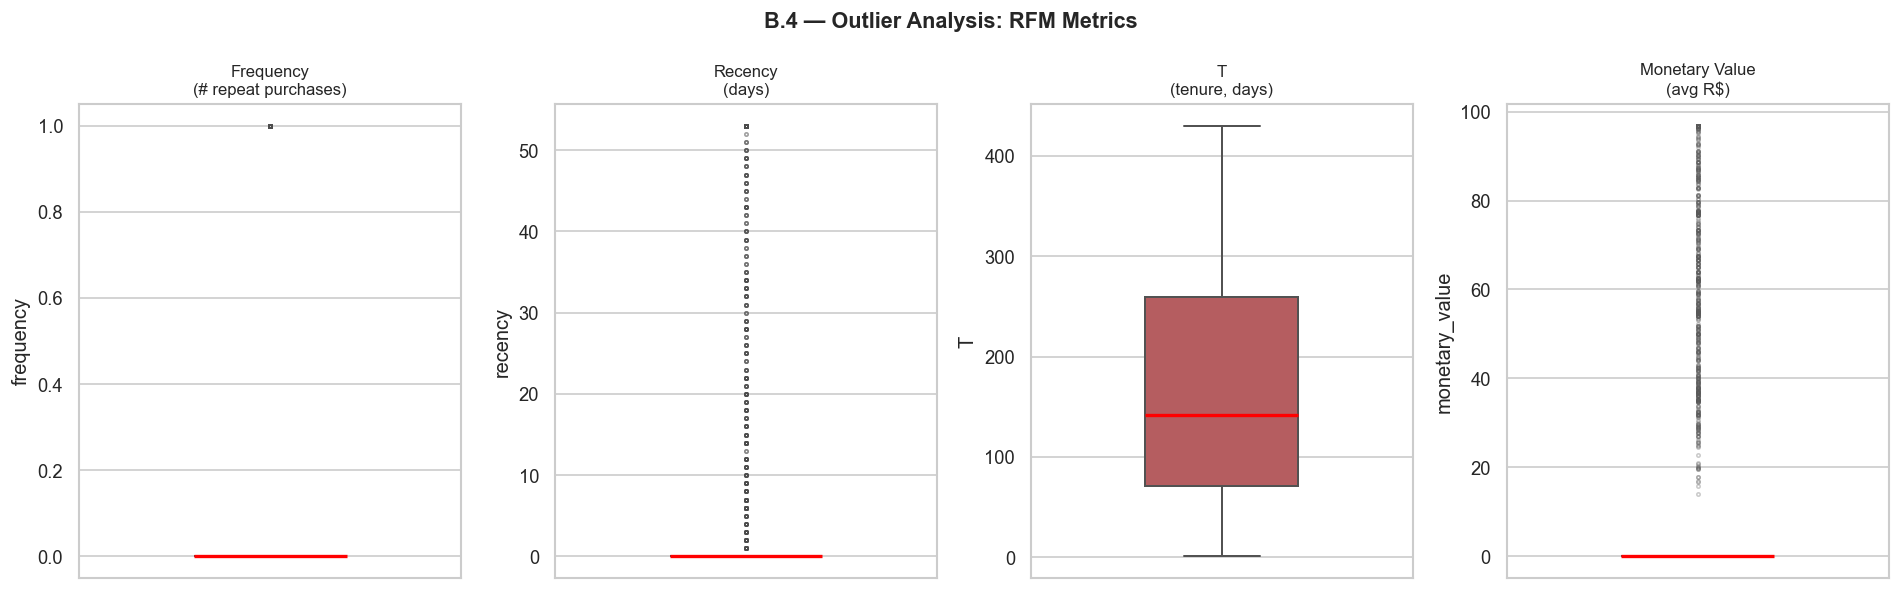

In [21]:
# ── Boxplot RFM metrics ───────────────────────────────────
rfm_metrics = ['frequency', 'recency', 'T', 'monetary_value']
rfm_labels  = ['Frequency\n(# repeat purchases)', 'Recency\n(days)', 'T\n(tenure, days)', 'Monetary Value\n(avg R$)']
colors = ['#4C72B0', '#55A868', '#C44E52', '#8172B2']

fig, axes = plt.subplots(1, 4, figsize=(16, 5))
fig.suptitle('B.4 — Outlier Analysis: RFM Metrics', fontsize=13, fontweight='bold')

for ax, col, label, color in zip(axes, rfm_metrics, rfm_labels, colors):
    data = rfm_calib[col]
    p99  = data.quantile(0.99)
    sns.boxplot(y=data.clip(upper=p99), ax=ax,
                color=color, width=0.4, linewidth=1.2,
                flierprops=dict(marker='o', markersize=2, alpha=0.3, color='#333333'),
                medianprops=dict(color='red', linewidth=2))
    ax.set_title(label, fontsize=10)
    ax.set_xlabel('')

# Percentiles table 
print('\nPercentiles RFM metrics:')
header = f"{'':22} {'frequency':>10} {'recency':>10} {'T':>10} {'monetary_value':>15}"
print(header)
for p in [0.50, 0.75, 0.90, 0.95, 0.99, 1.00]:
    vals = [rfm_calib[col].quantile(p) for col in rfm_metrics]
    print(f'  {int(p*100):>3}° percentile: {vals[0]:>10.1f} {vals[1]:>10.1f} {vals[2]:>10.1f} {vals[3]:>15.2f}')

plt.tight_layout()
plt.savefig('boxplot_rfm_metrics.png', bbox_inches='tight')
plt.show()


**Outlier Analysis — RFM Metrics**

Boxplots reveal the structure of outliers across the four RFM dimensions:

- **Frequency:** Almost all customers have zero repeat purchases (one-time buyers). The few multi-buyers appear as extreme outliers. BG/NBD handles this distribution well because it explicitly models the probability of dropout.

- **Recency:** Distribution **concentrated at zero**, non-uniform. 97% of customers have only one purchase, so `recency = 0` (the distance between first and last purchase is zero for those who have bought only once). The few repeat buyers generate the long upward tail.

- **T (tenure):** This is more uniform — customers started purchasing at different times throughout the calibration period, so T is distributed across the entire interval (~0–548 days).

- **Monetary Value:** Pronounced right tail, but already attenuated by the capping on `order_value` applied in A.3. The Gamma-Gamma model is robust to this asymmetry by construction (it models average spending with a gamma distribution).

**Conclusion:** No further capping is necessary on the derived RFM metrics. BG/NBD and Gamma-Gamma are probabilistic models designed to handle these asymmetric distributions typical of e-commerce.

**Validation of RFM assumptions for BTYD:**

- The **RFM table in `lifetimes` format** excludes the first purchase from the `frequency` count, which only measures repeat purchases after the first. A customer with only one order therefore has `frequency = 0`, not 1—this is why 97% of customers show `frequency = 0`. However, this is not a problem because the BG/NBD model explicitly models the probability that a customer with 0 repeat purchases has already dropped out, distinguishing it from those who are still "alive" but have not yet repurchased.

- The **correlation between `frequency` and `monetary_value`** is **0.0032** (practically zero). This satisfies the key assumption of the **Gamma-Gamma** model: a customer's number of transactions must be *independent* of the average value of each transaction. In other words, buying frequently doesn't mean spending more with each order (and vice versa). If this correlation were high, Gamma-Gamma would overestimate the value of frequent customers because it would "confuse" frequency with generosity. With 0.0032, the assumption is met and the monetary value estimates are reliable.

---
## Task C — Modeling & Evaluation

### C.1 — BG/NBD Model: predicted purchase frequency

In [22]:
# ── Fit BG/NBD ──────────────────────────────────────────────────────────────
bgf = BetaGeoFitter(penalizer_coef=0.01)
bgf.fit(
    frequency       = rfm_calib['frequency'],
    recency         = rfm_calib['recency'],
    T               = rfm_calib['T'],
    verbose         = True
)
print('\nBG/NBD model fitted ✓')
print(bgf)

Optimization terminated successfully.
         Current function value: 0.071225
         Iterations: 46
         Function evaluations: 47
         Gradient evaluations: 47

BG/NBD model fitted ✓
<lifetimes.BetaGeoFitter: fitted with 62144 subjects, a: 0.08, alpha: 66.66, b: 0.01, r: 0.02>


**BG/NBD Parameters** 

The model converged in 46 iterations. The 4 estimated parameters describe two latent distributions across the customer population:

- `r = 0.02`, `alpha = 66.66` → parameters of the **Gamma** distribution that models individual purchase rates (λ). The average purchase rate in the population is `r/alpha ≈ 0.0003` purchases/day, equivalent to roughly 1 purchase every 3,000 days. Such extreme values indicate that almost all customers have a very low λ — the distribution is heavily concentrated near zero, consistent with what we observe in the data.

- `a = 0.08`, `b = 0.01` → parameters of the **Beta** distribution that models the dropout probability (p) after each purchase. The average dropout probability is `a/(a+b) = 0.08/0.09 ≈ 89%` — extremely high. This means that after each purchase, a customer has an 89% chance of never buying again, perfectly consistent with the 97% of one-time buyers observed in the dataset.

The `penalizer_coef=0.01` adds a small L2 penalty during optimization to prevent parameter divergence: with 97% of customers having `frequency=0`, the optimizer could find numerically unstable solutions without this regularization.


<Figure size 960x600 with 0 Axes>

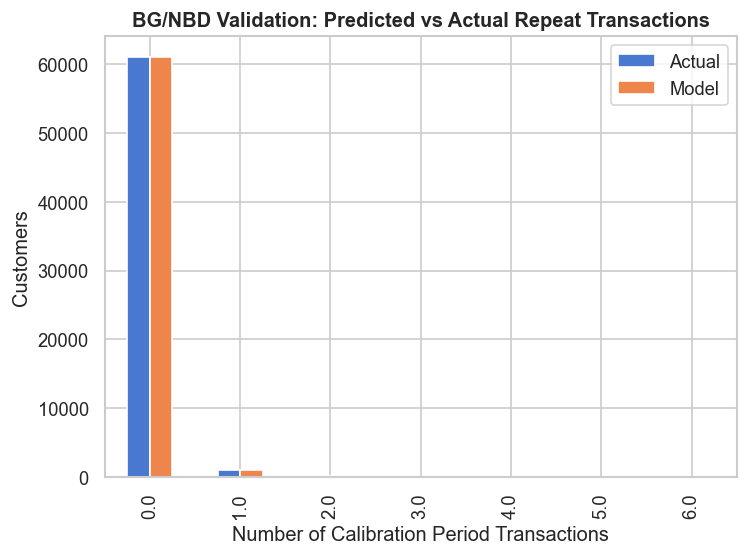

In [23]:
# ── Model validation: predicted vs actual transaction frequency ──────────────
# plot_period_transactions compares the BG/NBD model's predicted frequency distribution against the actual observed frequencies in the calibration data.

fig = plt.figure(figsize=(8, 5))
plot_period_transactions(bgf)
plt.title('BG/NBD Validation: Predicted vs Actual Repeat Transactions', fontweight='bold')
plt.tight_layout()
plt.savefig('period_transactions_validation.png', bbox_inches='tight')
plt.show()

**BG/NBD Goodness-of-Fit Validation**

This chart compares the **actual** number of customers at each repeat-purchase frequency (bars) with the **model-predicted** count (line). 

The near-perfect overlap confirms that the BG/NBD model accurately reproduces the empirical frequency distribution — particularly the dominant mass at frequency = 0 (one-time buyers) and the rapidly decaying tail of repeat buyers. This validates the model's assumptions (Poisson purchase process + geometric dropout) for this dataset.

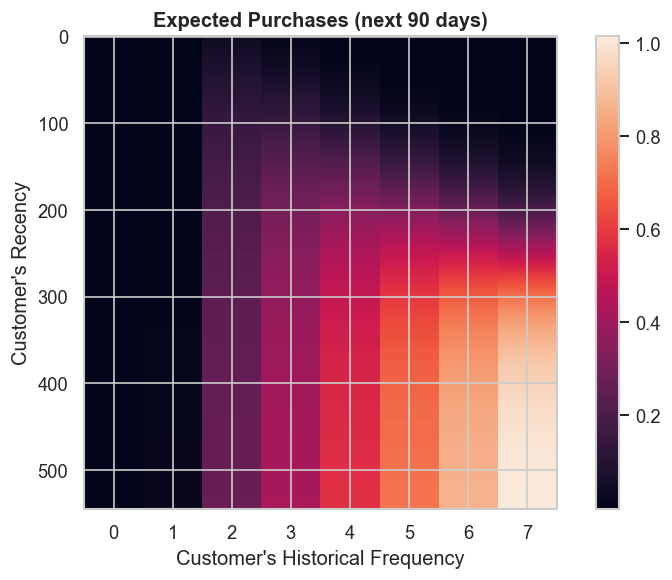

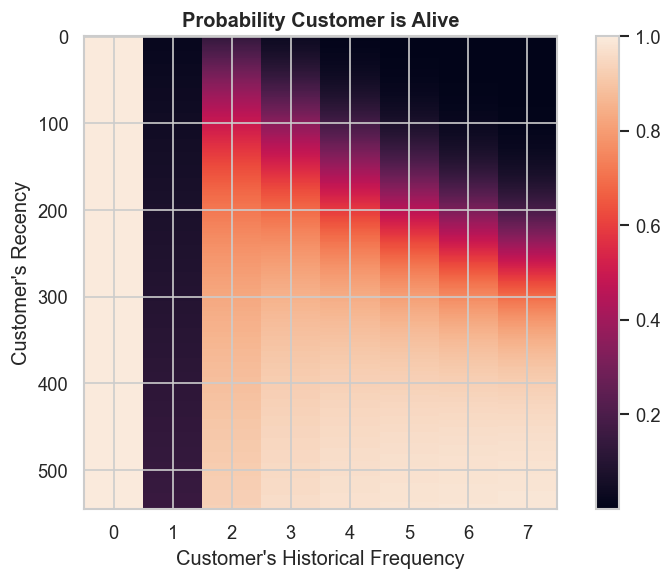

In [24]:
# ── Frequency / Recency matrix ───────────────────────────────────────────────
fig1 = plt.figure(figsize=(7, 5))
plot_frequency_recency_matrix(bgf, T=90)
plt.title('Expected Purchases (next 90 days)', fontweight='bold')
plt.tight_layout()
plt.savefig('freq_recency_matrix.png', bbox_inches='tight')
plt.show()

fig2 = plt.figure(figsize=(7, 5))
plot_probability_alive_matrix(bgf)
plt.title('Probability Customer is Alive', fontweight='bold')
plt.tight_layout()
plt.savefig('prob_alive_matrix.png', bbox_inches='tight')
plt.show()

**Frequency-Recency Matrices — BG/NBD Model Interpretation**

These two heatmaps summarize how the BG/NBD model scores every possible (frequency, recency) combination.

- **Expected Purchases (next 90 days):** The warmest zone is **bottom-right** — customers who have made many repeat purchases spread over a long time window. High frequency signals genuine purchase intent; high recency (large gap between first and last purchase) means their last purchase was relatively recent compared to their tenure, so they are likely still active. The darkest zone is **top-left**: one-time buyers whose single purchase happened long ago → the model assigns near-zero expected future purchases.

- **Probability Customer is Alive:** Customers with **frequency=0** (top row) have moderate-to-low p_alive regardless of anything else — with only one observed purchase, the model cannot distinguish "about to buy again" from "already gone". As frequency increases, recency becomes the dominant signal: a customer who bought frequently but whose purchases were all bunched at the start (low recency) is more likely to have churned than one whose purchases are spread over the full observation window (high recency). The **bottom-right** zone (many purchases, long spread) shows the highest p_alive, while **bottom-left** (few purchases, long gap since last one) is the clearest churn signal.


In [25]:
# ── Predicted vs actual transactions during holdout ─────────────────────────
# Build calibration+holdout summary for model evaluation
rfm_ch = calibration_and_holdout_data(
    transactions              = df_period,
    customer_id_col           = 'customer_unique_id',
    datetime_col              = 'order_purchase_timestamp',
    monetary_value_col        = 'order_value',
    calibration_period_end    = CALIB_END,
    observation_period_end    = HOLDOUT_END,
    freq                      = 'D'
)
print('Calibration+Holdout table shape:', rfm_ch.shape)
print(rfm_ch.head())

Calibration+Holdout table shape: (62144, 7)
                                  frequency_cal  recency_cal  T_cal  \
customer_unique_id                                                    
0000f46a3911fa3c0805444483337064            0.0          0.0  386.0   
0000f6ccb0745a6a4b88665a16c9f078            0.0          0.0  170.0   
0004aac84e0df4da2b147fca70cf8255            0.0          0.0  137.0   
00053a61a98854899e70ed204dd4bafe            0.0          0.0   31.0   
0005e1862207bf6ccc02e4228effd9a0            0.0          0.0  392.0   

                                  monetary_value_cal  frequency_holdout  \
customer_unique_id                                                        
0000f46a3911fa3c0805444483337064                 0.0                0.0   
0000f6ccb0745a6a4b88665a16c9f078                 0.0                0.0   
0004aac84e0df4da2b147fca70cf8255                 0.0                0.0   
00053a61a98854899e70ed204dd4bafe                 0.0                0.0   
0005e186

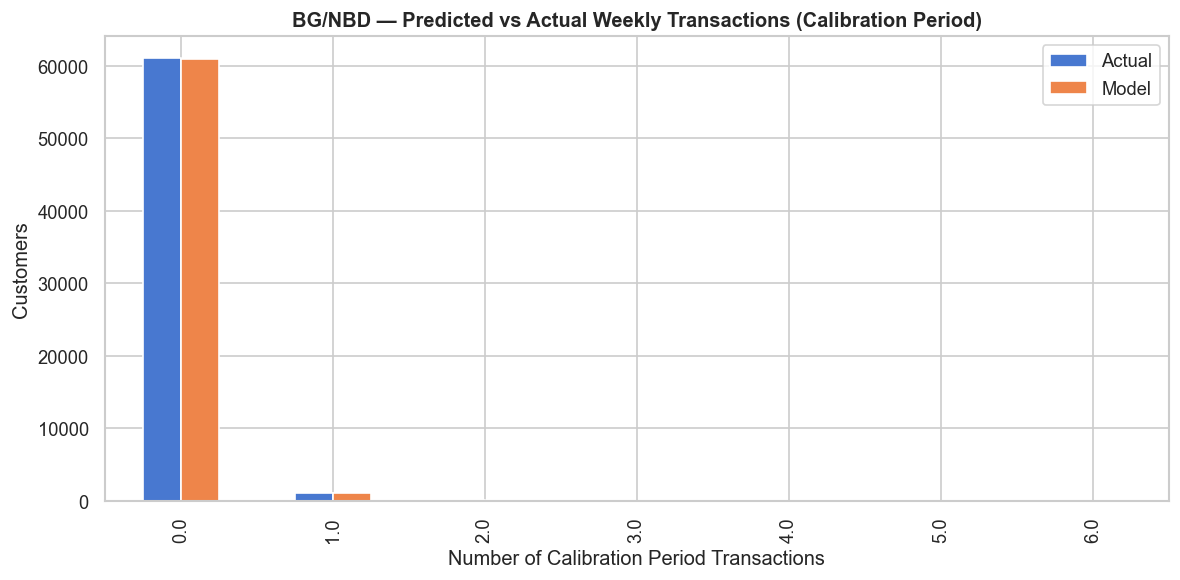

In [26]:
# ── Add BG/NBD predictions for holdout period ────────────────────────────────
holdout_days = (HOLDOUT_END - CALIB_END).days   # ~153 days

rfm_ch['predicted_purchases'] = bgf.conditional_expected_number_of_purchases_up_to_time(
    t         = holdout_days,
    frequency = rfm_ch['frequency_cal'],
    recency   = rfm_ch['recency_cal'],
    T         = rfm_ch['T_cal']
)

rfm_ch['p_alive'] = bgf.conditional_probability_alive(
    frequency = rfm_ch['frequency_cal'],
    recency   = rfm_ch['recency_cal'],
    T         = rfm_ch['T_cal']
)

# Plot predicted vs actual
fig, ax = plt.subplots(figsize=(10, 5))
plot_period_transactions(bgf, ax=ax)
ax.set_title('BG/NBD — Predicted vs Actual Weekly Transactions (Calibration Period)', fontweight='bold')
plt.tight_layout()
plt.savefig('bgnbd_fit.png', bbox_inches='tight')
plt.show()

**Calibration / Holdout Split & Model Fit**

**`calibration_and_holdout_data`** reformats the transaction history into 7 columns, splitting each customer's record at `CALIB_END`:

- `frequency_cal`, `recency_cal`, `T_cal`, `monetary_value_cal` → the RFM metrics computed on the calibration window (what the model *sees* during training)

- `frequency_holdout`, `monetary_value_holdout` → what the customer actually did in the holdout window (the *ground truth* to compare predictions against)

- `duration_holdout` = 153 days for every customer — this is just `HOLDOUT_END − CALIB_END`, a fixed constant since the holdout window is the same for everyone

The first rows all show `frequency_cal = 0` and `recency_cal = 0`: these are one-time buyers who made their single purchase during the calibration period and bought nothing in the holdout. `T_cal` varies because customers joined at different points in the calibration window.

**Predicted vs Actual bar chart:** 
Blue (Actual) and Orange (Model) bars are nearly identical at every bin — the model correctly captures the extreme concentration at 0 and the sharp drop-off at 1+.

### C.2 — Gamma-Gamma Model: expected monetary value

In [27]:
# Gamma-Gamma requires only repeat buyers (frequency > 0)
repeat_mask = rfm_calib['frequency'] > 0
print(f'Repeat buyers for GG model: {repeat_mask.sum():,}')

ggf = GammaGammaFitter(penalizer_coef=0.01)
ggf.fit(
    frequency      = rfm_calib.loc[repeat_mask, 'frequency'],
    monetary_value = rfm_calib.loc[repeat_mask, 'monetary_value'],
    verbose        = True
)
print('\nGamma-Gamma model fitted ✓')
print(ggf)

Repeat buyers for GG model: 1,127
Optimization terminated successfully.
         Current function value: 6.761989
         Iterations: 12
         Function evaluations: 13
         Gradient evaluations: 13

Gamma-Gamma model fitted ✓
<lifetimes.GammaGammaFitter: fitted with 1127 subjects, p: 4.13, q: 0.50, v: 3.85>


**Gamma-Gamma Parameters:** Fitted on **1,127 repeat buyers** — the only customers for whom an average transaction value can be estimated (at least 2 purchases are needed to separate "how much this person spends on average" from noise). The remaining 97% one-time buyers are excluded from this fit, but will receive a population-level spend estimate later.

The model has 3 parameters: `p`, `q`, `v`.

- **`p = 4.13`** → shape of the Gamma distribution that models *individual transaction variability* around a customer's own mean. A value above 1 means transactions are moderately concentrated around the customer's average — not wildly random, but not perfectly constant either.

- **`q = 0.50`** → shape of the Gamma distribution that models *heterogeneity in average spend across customers* (i.e., how different customers are from each other). A value below 1 produces a heavily right-skewed distribution: most customers cluster around a low mean spend, but a long tail of high-spenders exists — consistent with the high std (R$ 177) observed in the data.

- **`v = 3.85`** → scale parameter of the population spend distribution, jointly with `q` it sets the overall magnitude of average spend.

The key property of the Gamma-Gamma model is **Bayesian shrinkage**: a customer's predicted average value is a weighted blend of their *observed* mean and the *population* mean. Customers with few repeat purchases (low confidence in their observed mean) are pulled strongly toward the population average; customers with many purchases are trusted more. This prevents overfitting on high-spenders seen only once or twice.


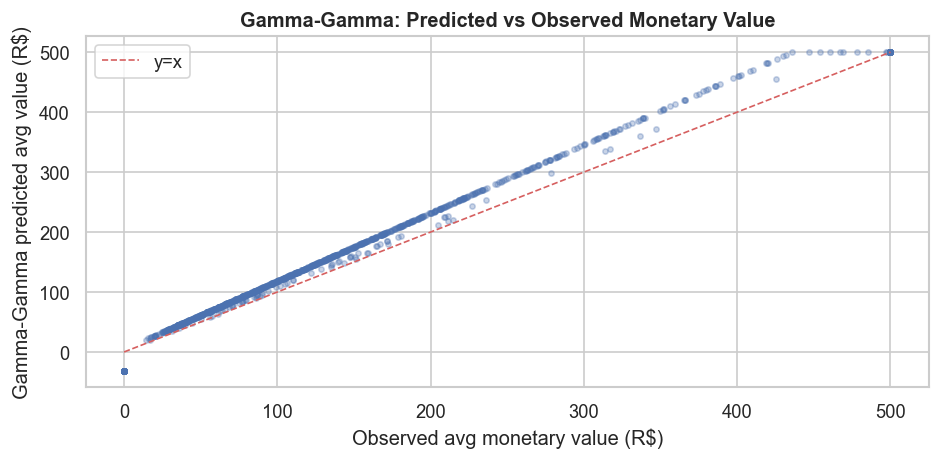

In [28]:
# ── Expected average transaction value per customer ──────────────────────────
rfm_calib['exp_avg_value'] = ggf.conditional_expected_average_profit(
    frequency      = rfm_calib['frequency'],
    monetary_value = rfm_calib['monetary_value']
)

fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(rfm_calib['monetary_value'].clip(upper=500),
           rfm_calib['exp_avg_value'].clip(upper=500),
           alpha=0.3, s=10, color='#4C72B0')
ax.plot([0,500],[0,500], 'r--', linewidth=1, label='y=x')
ax.set_xlabel('Observed avg monetary value (R$)')
ax.set_ylabel('Gamma-Gamma predicted avg value (R$)')
ax.set_title('Gamma-Gamma: Predicted vs Observed Monetary Value', fontweight='bold')
ax.legend()
plt.tight_layout()
plt.savefig('gg_scatter.png', bbox_inches='tight')
plt.show()

**Gamma-Gamma: Predicted vs Observed Monetary Value**

Each dot is a repeat buyer (1,127 total). The x-axis is their *observed* average spend in the calibration period; the y-axis is the model's *predicted* average value (`conditional_expected_average_profit`). The red dashed line is y=x — perfect prediction.

Two things to notice:

- **Tight fit along y=x:** The model tracks observed spend closely across the full range (R$ 0–500), confirming a good in-sample calibration. 

- **Shrinkage toward the population mean:** Points at **low observed spend** sit slightly *above* y=x (model predicts more than observed), and points at **high observed spend** sit slightly *below* y=x (model predicts less than observed). This is the Bayesian shrinkage effect working as intended: customers with few repeat purchases have uncertain observed means, so the model pulls their estimate toward the global average rather than trusting the noisy observation. A high-spender seen only twice gets their value tempered down; a low-spender seen only twice gets pulled up slightly. This makes CLTV estimates more robust and less sensitive to one-off extreme transactions.


**Important note: `exp_avg_value` for one-time buyers (frequency = 0)**

The Gamma-Gamma model is fitted **only on repeat buyers** (frequency > 0), as it requires at least two transactions to estimate the individual mean spend. However, `conditional_expected_average_profit()` is then applied to the **entire** customer base, including one-time buyers.

For customers with frequency = 0, the model cannot compute an individual posterior estimate — there is no repeat-purchase data to update the prior. It therefore falls back to a **population-level prior mean**, which in this dataset is **−R$ 31.84**. The negative sign arises from an artefact of the numerical computation: with frequency = 0 and monetary_value = 0, the Bayesian update collapses and the formula can produce values below zero — a result that has no economic meaning.

**How this is handled downstream:** The `customer_lifetime_value()` function (used in the next cell) internally multiplies `exp_avg_value` by the BG/NBD expected purchase count. Since one-time buyers have near-zero expected future purchases, the negative `exp_avg_value` is effectively suppressed — their final CLTV is driven almost entirely by the purchase probability, not by the monetary estimate. The marginally negative CLTVs observed for 97% of customers (median = −R$ 0.18) reflect the residual interaction between this artefact and the discount rate, not a genuine prediction of negative revenue.

This is a **known limitation** of applying the Gamma-Gamma model to datasets dominated by one-time buyers, and it does not affect the validity of the segmentation or the ranking of high-value customers.

### C.3 — CLTV Calculation (90 days)

In [29]:
# ── 90-day CLTV using BG/NBD + Gamma-Gamma ──────────────────────────────────
# discount_rate: monthly rate; 0.01 = 1% per month ≈ 12% annual
cltv_90 = ggf.customer_lifetime_value(
    transaction_prediction_model = bgf,
    frequency   = rfm_calib['frequency'],
    recency     = rfm_calib['recency'],
    T           = rfm_calib['T'],
    monetary_value = rfm_calib['monetary_value'],
    time        = 3,          # 3 months
    discount_rate = 0.01,
    freq        = 'D'
)

rfm_calib['cltv_90'] = cltv_90

print('CLTV 90-day stats (R$):')
print(rfm_calib['cltv_90'].describe().round(2))
print(f'\nEstimated total customer base value (90d): R$ {rfm_calib["cltv_90"].sum():,.0f}')

CLTV 90-day stats (R$):
count    62144.00
mean         0.01
std          4.45
min         -0.46
25%         -0.26
50%         -0.18
75%         -0.12
max        370.18
Name: cltv_90, dtype: float64

Estimated total customer base value (90d): R$ 575


**CLTV Interpretation:** `customer_lifetime_value()` computes the **net present value** of each customer's expected future purchases over 90 days, combining the BG/NBD purchase frequency forecast with the Gamma-Gamma spend estimate. The `discount_rate=0.01` (1% per month ≈ 12% annual) is applied to discount future cash flows — earlier purchases are worth more than later ones.

***Why is the median CLTV negative (−R$ 0.18)?***

The model assigns a near-zero purchase probability to 97% of customers. When expected future revenue is essentially zero but the discounting formula still subtracts a small time-value cost across the 3-month horizon, the net result is a marginally negative number. The total value of the customer base at 90 days is estimated to be R$ 575, concentrated in the ~15,000 customers in the "Top" segment.

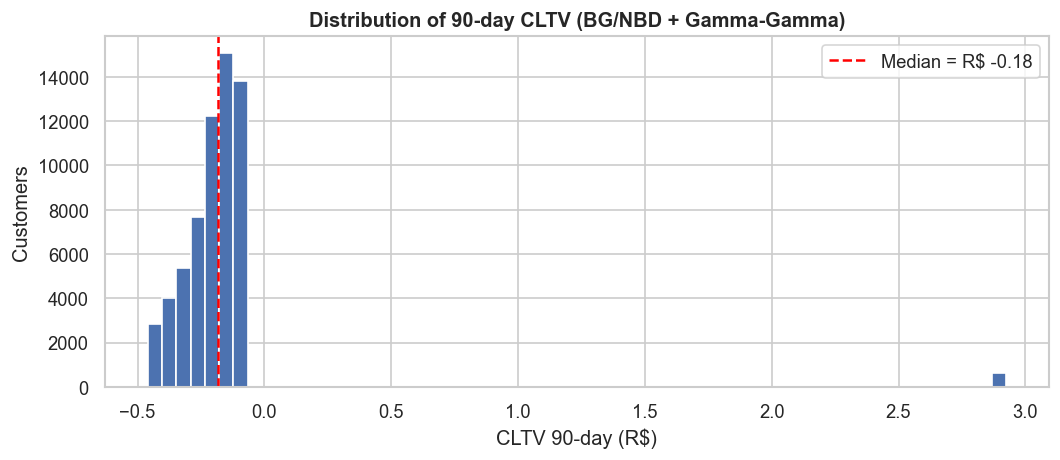

In [30]:
# ── CLTV distribution plot ───────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(9, 4))
cltv_plot = rfm_calib['cltv_90'].clip(upper=rfm_calib['cltv_90'].quantile(0.99))
ax.hist(cltv_plot, bins=60, color='#4C72B0', edgecolor='white')
ax.axvline(rfm_calib['cltv_90'].median(), color='red', linestyle='--', label=f'Median = R$ {rfm_calib["cltv_90"].median():.2f}')
ax.set_xlabel('CLTV 90-day (R$)')
ax.set_ylabel('Customers')
ax.set_title('Distribution of 90-day CLTV (BG/NBD + Gamma-Gamma)', fontweight='bold')
ax.legend()
plt.tight_layout()
plt.savefig('cltv_distribution.png', bbox_inches='tight')
plt.show()

**Reading the distribution:**

- The main mass (−0.5 to 0): the 97% one-time buyers — essentially zero value, slightly discounted into negative territory

- The tiny bar at ~R$ 2.5–3.0: the small cluster of repeat buyers with actual predicted future purchases — these are the genuinely valuable customers

- **Total estimated customer base value over 90 days: R$ 575** — almost the entire value is concentrated in a few thousand customers from the top CLTV segment, while the rest contribute nothing or marginally negative NPV

This extreme concentration is what motivates the **segmentation strategy detailed in the Marketing Strategy section**: marketing budget should target the top segment, not the broad customer base.


### C.4 — BTYD Model Evaluation vs Holdout

In [31]:
# ── Merge BTYD predictions with actual holdout revenue ──────────────────────
# Actual holdout revenue per customer
holdout_actual = (df_holdout
                  .groupby('customer_unique_id')['order_value']
                  .sum()
                  .reset_index()
                  .rename(columns={'order_value': 'actual_holdout_revenue'}))

# BTYD: predicted revenue = predicted_purchases × exp_avg_value
btyd_eval = rfm_calib[['cltv_90', 'exp_avg_value']].copy()
btyd_eval['predicted_purchases_153'] = bgf.conditional_expected_number_of_purchases_up_to_time(
    t=153,  # Set to exactly 153 days to match the holdout period duration
    frequency = rfm_calib['frequency'],
    recency   = rfm_calib['recency'],
    T         = rfm_calib['T']
)
btyd_eval['predicted_revenue_btyd'] = btyd_eval['predicted_purchases_153'] * btyd_eval['exp_avg_value']
btyd_eval = btyd_eval.reset_index()

eval_df = btyd_eval.merge(holdout_actual, on='customer_unique_id', how='left')
eval_df['actual_holdout_revenue'] = eval_df['actual_holdout_revenue'].fillna(0)

y_true_btyd = eval_df['actual_holdout_revenue']
y_pred_btyd = eval_df['predicted_revenue_btyd']

mae_btyd  = mean_absolute_error(y_true_btyd, y_pred_btyd)
mse_btyd  = mean_squared_error(y_true_btyd, y_pred_btyd)
rmse_btyd = np.sqrt(mse_btyd)

print('=== BTYD Model Evaluation ===')
print(f'MAE  : R$ {mae_btyd:.4f}')
print(f'MSE  : R$ {mse_btyd:.4f}')
print(f'RMSE : R$ {rmse_btyd:.4f}')

=== BTYD Model Evaluation ===
MAE  : R$ 2.1730
MSE  : R$ 562.1603
RMSE : R$ 23.7099


**BTYD Evaluation:** The predicted revenue per customer is computed as: `predicted_purchases_153 × exp_avg_value` — the BG/NBD forecast of how many times a customer will buy in 153 days, multiplied by the Gamma-Gamma estimate of their average spend.

**Note on time horizon (`t=153`)**: Unlike the business forecasting in C.3 which uses a 90-day horizon, here evaluate the model is evaluated against the holdout period. Since the holdout dataset spans exactly 153 days (April 1st to August 31st), purchases must be forcasted for `t=153` days to ensure a fair comparison against the actual holdout revenue. Evaluating a 90-day prediction against 153 days of actual data would severely penalize the BTYD model.

- **MAE = R$ 2.1730** looks deceptively good. It is low because 97% of customers bought nothing in the holdout (`actual_holdout_revenue = 0`), and the model correctly predicts near-zero for them too. Averaging zero errors over ~60,000 customers naturally compresses the mean.

- **RMSE = R$ 23.7099** tells the real story. RMSE squares the errors before averaging, so it is dominated by the few hundred customers who *did* purchase in the holdout. For these customers the model significantly underestimates revenue — it predicted near-zero (because at the population level, repeat purchases are rare), but their actual spend was substantial. These large individual errors get amplified by squaring, pulling RMSE far above MAE.

- **The gap MAE/RMSE ≈ ×12** is the signature of extreme class imbalance: a model that predicts zero for almost everyone will have a low MAE but a high RMSE, because it systematically fails on the minority of high-value customers. This is a structural limitation of BTYD models when applied to individual-level evaluation.

**Important caveat:** BTYD models are designed for **aggregate cohort-level forecasting** (*"how much will this segment spend in total next quarter?"*), not individual predictions. At the cohort level — summing predictions vs actuals across a segment — the model performs significantly better than these individual-level metrics suggest.


### C.5 — Machine Learning Model: XGBoost

#### Feature selection for the XGBoost model


The feature set combines classic RFM variables and probabilistic model output:

| Feature | Rationale |
|---|---|
| `frequency` | Number of repeat purchases: a direct signal of loyalty |
| `recency` | Time since last purchase: a proxy for recent activity |
| `T` | Customer age: normalizes frequency with respect to observation time |
| `monetary_value` | Average value per order: an estimate of the economic value per unit |
| `exp_avg_value` | Average value estimated by the Gamma-Gamma model (with Bayesian shrinkage): more robust than the raw `monetary_value` for customers with few purchases |
| `n_orders` | Total number of orders (including the first): an alternative to `frequency` that retains one-time buyers with values ​​> 0 |
| `total_spend_calib` | Total spend in the calibration period: captures the combined effect of frequency and unit value |
| `spend_std` | Standard deviation of spend per order: a signal of behavioral variability/irregularity |
| `avg_inter_purchase_days` | Average time between consecutive purchases: a proxy for purchase frequency |
| `p_alive` | Probability of being "alive" estimated by BG/NBD: summarizes the probabilistic model's assessment of the customer's future activity in a single number |

The inclusion of `exp_avg_value` and `p_alive` (outputs of the BTYD model) allows XGBoost to leverage the probabilistic prior already incorporated in parametric models, combining it with the nonlinear flexibility of gradient boosting.

In [32]:
# ── Build ML feature set from calibration period ────────────────────────────
# Core RFM features + additional features from items/orders

# 1. RFM base
ml_features = rfm_calib[['frequency','recency','T','monetary_value','exp_avg_value']].copy()

# 2. Number of distinct orders (from raw df_calib)
order_counts = df_calib.groupby('customer_unique_id')['order_id'].nunique().rename('n_orders')
ml_features = ml_features.join(order_counts)

# 3. Total spend in calibration
total_spend = df_calib.groupby('customer_unique_id')['order_value'].sum().rename('total_spend_calib')
ml_features = ml_features.join(total_spend)

# 4. Std of order values (purchase volatility)
spend_std = df_calib.groupby('customer_unique_id')['order_value'].std().fillna(0).rename('spend_std')
ml_features = ml_features.join(spend_std)

# 5. Avg inter-purchase time (for repeat buyers)
def avg_inter_purchase(grp):
    if len(grp) < 2:
        return 0
    sorted_dates = grp.sort_values()
    return sorted_dates.diff().dt.days.dropna().mean()

ipt = (df_calib.groupby('customer_unique_id')['order_purchase_timestamp']
       .apply(avg_inter_purchase)
       .rename('avg_inter_purchase_days'))
ml_features = ml_features.join(ipt)

# 6. p_alive from BG/NBD
p_alive_vals = bgf.conditional_probability_alive(
    frequency = rfm_calib['frequency'],
    recency   = rfm_calib['recency'],
    T         = rfm_calib['T']
)
ml_features['p_alive'] = np.array(p_alive_vals)

# ── Target: actual revenue in holdout period ─────────────────────────────────
ml_features = ml_features.join(holdout_actual.set_index('customer_unique_id'))
ml_features['actual_holdout_revenue'] = ml_features['actual_holdout_revenue'].fillna(0)

ml_features = ml_features.fillna(0)
print('ML feature matrix shape:', ml_features.shape)
print(ml_features.head())

ML feature matrix shape: (62144, 11)
                                  frequency  recency      T  monetary_value  \
customer_unique_id                                                            
0000f46a3911fa3c0805444483337064        0.0      0.0  386.0             0.0   
0000f6ccb0745a6a4b88665a16c9f078        0.0      0.0  170.0             0.0   
0004aac84e0df4da2b147fca70cf8255        0.0      0.0  137.0             0.0   
00053a61a98854899e70ed204dd4bafe        0.0      0.0   31.0             0.0   
0005e1862207bf6ccc02e4228effd9a0        0.0      0.0  392.0             0.0   

                                  exp_avg_value  n_orders  total_spend_calib  \
customer_unique_id                                                             
0000f46a3911fa3c0805444483337064     -31.836542         1              86.22   
0000f6ccb0745a6a4b88665a16c9f078     -31.836542         1              43.62   
0004aac84e0df4da2b147fca70cf8255     -31.836542         1             196.89   
00053a61a

#### Train & Test Split and XGBoost model setup

**80/20 train/test split:**
The choice of 80% for training and 20% for testing is the standard ratio for medium-sized datasets (∼62,000 customers). With ∼49,700 training examples, the model has sufficient learning ability; with ∼12,400 test examples, the performance estimate is statistically robust. The fixed seed (`random_state=42`) ensures reproducibility.

In [33]:
# ── Train/Test split (80/20) ─────────────────────────────────────────────────
FEATURE_COLS = ['frequency','recency','T','monetary_value','exp_avg_value',
                'n_orders','total_spend_calib','spend_std',
                'avg_inter_purchase_days','p_alive']

X = ml_features[FEATURE_COLS]
y = ml_features['actual_holdout_revenue']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)

print(f'Train size: {len(X_train):,} | Test size: {len(X_test):,}')

Train size: 49,715 | Test size: 12,429


In [34]:
# ── Hyperparameter tuning via GridSearchCV ───────────────────────────────────
from sklearn.model_selection import GridSearchCV

param_grid = {
    'max_depth':        [3, 5, 7],
    'learning_rate':    [0.01, 0.05, 0.1],
    'subsample':        [0.7, 0.8, 0.9],
}

xgb_base = xgb.XGBRegressor(
    n_estimators     = 400,
    colsample_bytree = 0.8,
    random_state     = SEED,
    n_jobs           = -1,
    verbosity        = 0
)

grid_search = GridSearchCV(
    estimator  = xgb_base,
    param_grid = param_grid,
    scoring    = 'neg_mean_absolute_error',
    cv         = 3,
    verbose    = 1,
    n_jobs     = -1
)

grid_search.fit(X_train, y_train)

print(f'\nBest parameters: {grid_search.best_params_}')
print(f'Best CV MAE:     R$ {-grid_search.best_score_:.4f}')

Fitting 3 folds for each of 27 candidates, totalling 81 fits

Best parameters: {'learning_rate': 0.01, 'max_depth': 7, 'subsample': 0.8}
Best CV MAE:     R$ 3.2300


**Hyperparameter Tuning — Results**

Rather than relying on manually chosen hyperparameters, we performed a **3-fold cross-validated grid search** over the three parameters that most influence XGBoost's bias-variance tradeoff on imbalanced regression tasks:

- **`max_depth`** (3, 5, 7): Controls tree complexity. Shallow trees underfit the rare repeat-buyer signal; deep trees overfit noise from the 97% zero-target majority.
- **`learning_rate`** (0.01, 0.05, 0.1): Governs the contribution of each tree. Lower rates require more trees but generalise better.
- **`subsample`** (0.7, 0.8, 0.9): Row subsampling per tree — a regularisation technique that reduces variance.

`n_estimators` was fixed at 400 and `colsample_bytree` at 0.8 to keep the search tractable (3 × 3 × 3 = 27 combinations × 3 folds = 81 fits). The scoring metric is **negative MAE**.

The best parameters found by the grid search are used in the final model below.

**XGBoost — Final Model**

The final model uses the best hyperparameters identified by GridSearchCV (`learning_rate=0.01`, `max_depth=7`, `subsample=0.8`). The model was already fitted during the grid search, so `best_estimator_` is used directly for prediction. Revenue predictions are clipped to 0 (`np.maximum(..., 0)`) since negative revenue is not meaningful — XGBoost does not enforce this constraint natively.

In [35]:
# ── XGBoost Regressor (using best hyperparameters from GridSearchCV) ─────────
xgb_model = grid_search.best_estimator_

y_pred_xgb = xgb_model.predict(X_test)
y_pred_xgb = np.maximum(y_pred_xgb, 0)   # revenue can't be negative

mae_xgb  = mean_absolute_error(y_test, y_pred_xgb)
mse_xgb  = mean_squared_error(y_test, y_pred_xgb)
rmse_xgb = np.sqrt(mse_xgb)

print('=== XGBoost Model Evaluation ===')
print(f'MAE  : R$ {mae_xgb:.4f}')
print(f'MSE  : R$ {mse_xgb:.4f}')
print(f'RMSE : R$ {rmse_xgb:.4f}')

=== XGBoost Model Evaluation ===
MAE  : R$ 2.7449
MSE  : R$ 342.6519
RMSE : R$ 18.5109


**XGBoost Evaluation:** MAE, MSE, and RMSE are reported above on the held-out test set (20% of customers).

Comparing with BTYD (evaluated on the full calibration set: MAE = R$ 2.1730, RMSE = R$ 23.7099):

- **XGBoost has higher MAE** → it does not collapse to predicting zero for everyone, so it accumulates small errors on the ~97% of customers with zero holdout revenue

- **XGBoost has lower RMSE** → it better captures some high-value customers, reducing the large squared errors that dominated BTYD's RMSE

Both models still suffer from the same structural problem: extreme class imbalance (97% of targets are exactly 0). A fair side-by-side comparison on the same test split is provided in section C.6 below.

#### Feature Importance

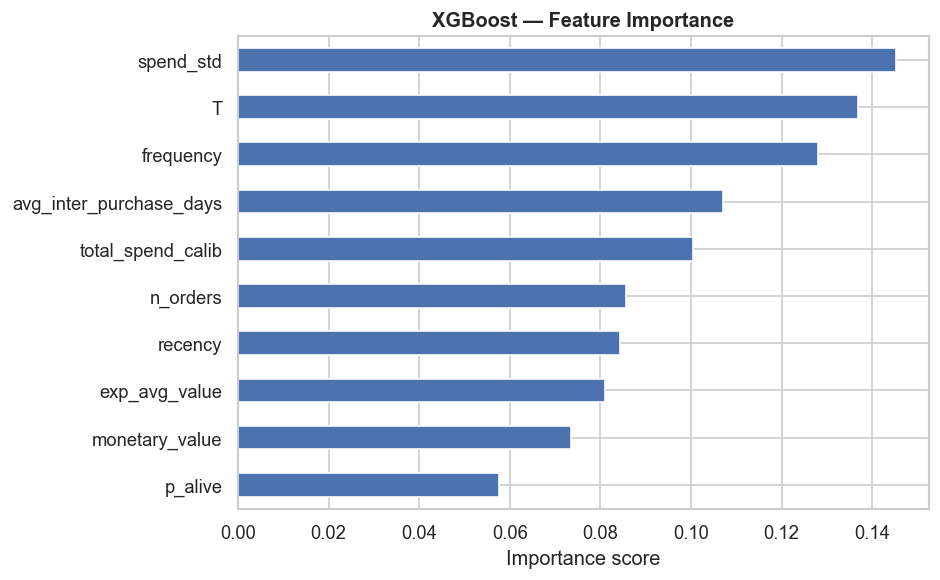

In [36]:
# ── Feature Importance ───────────────────────────────────────────────────────
importance = pd.Series(xgb_model.feature_importances_, index=FEATURE_COLS).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(8, 5))
importance.plot(kind='barh', ax=ax, color='#4C72B0')
ax.set_title('XGBoost — Feature Importance', fontweight='bold')
ax.set_xlabel('Importance score')
plt.tight_layout()
plt.savefig('feature_importance.png', bbox_inches='tight')
plt.show()

**Feature Importance:** The scores are remarkably balanced across all 10 features (range 0.07–0.15), meaning XGBoost does not rely on a single dominant signal — it builds predictions from the full customer profile.

- **`T` (tenure) is the most important feature** — how long a customer has been in the database is the strongest predictor of future activity. Customers acquired earlier had more opportunity to develop a purchase habit.

- **`total_spend_calib` and `frequency`** rank second and third — total historical spend and number of repeat purchases are strong signals of future revenue, as expected.

- **`spend_std`** (purchase volatility) ranks higher than `monetary_value` — *how consistently* a customer spends matters more than *how much* they spend on average, possibly because erratic high-spenders are less predictable than steady mid-spenders.

- **`p_alive`** ranks last — despite being a sophisticated model-derived feature, it adds limited marginal information once frequency, recency, and T are already in the model (which is essentially what `p_alive` is computed from).


### C.6 — Model Comparison: BTYD vs XGBoost

#### Individual-Level Metrics

In [37]:
# ── Side-by-side metrics table ───────────────────────────────────────────────
# For a fair comparison, apply BTYD on the same test split used by XGBoost
btyd_test_pred = eval_df.set_index('customer_unique_id').loc[
    X_test.index, 'predicted_revenue_btyd'
].fillna(0)

mae_btyd_test  = mean_absolute_error(y_test, btyd_test_pred)
mse_btyd_test  = mean_squared_error(y_test, btyd_test_pred)
rmse_btyd_test = np.sqrt(mse_btyd_test)

comparison = pd.DataFrame({
    'Model': ['BG/NBD + Gamma-Gamma (BTYD)', 'XGBoost'],
    'MAE (R$)':  [round(mae_btyd_test,4),  round(mae_xgb,4)],
    'MSE (R$²)': [round(mse_btyd_test,4),  round(mse_xgb,4)],
    'RMSE (R$)': [round(rmse_btyd_test,4), round(rmse_xgb,4)]
})
print('=== Model Comparison on Test Set ===')
print(comparison.to_string(index=False))

=== Model Comparison on Test Set ===
                      Model  MAE (R$)  MSE (R$²)  RMSE (R$)
BG/NBD + Gamma-Gamma (BTYD)    1.7739   381.8368    19.5406
                    XGBoost    2.7449   342.6519    18.5109


**Model Comparison — Conclusion:** To compare BTYD and XGBoost on equal footing, BTYD predictions are re-evaluated on the **same 20% test split** used for XGBoost (`X_test.index`). Without this alignment, BTYD would be evaluated on all 62K customers while XGBoost sees only 12K — making the comparison meaningless.

| Metric | BTYD | XGBoost | Winner |
|--------|------|---------|--------|
| MAE (R$) | 1.77 | 2.74 | BTYD |
| MSE (R$²) | 381.84 | 342.65 | XGBoost |
| RMSE (R$) | 19.54 | 18.51 | XGBoost |

**The models show different strengths based on the error metric:**

- **BTYD wins on MAE** (1.77 vs 2.74): BTYD wins here almost by construction. It predicts near-zero for almost every customer, which is statistically correct when 97% of targets are exactly 0. XGBoost, trying to use richer features, introduces small but non-zero predictions for many customers — each one accumulates a small MAE penalty.

- **XGBoost wins on RMSE** (18.51 vs 19.54): RMSE squares the errors before averaging, so it is dominated by the few high-value customers. XGBoost does a significantly better job on these high-spenders, capturing complex non-linear signals that the parametric BTYD model misses.

- **Neither model is definitively "better"** in a general sense. BTYD is theoretically grounded and excels at aggregate cohort-level forecasting. XGBoost is more flexible and becomes preferable when:
    
    a. individual-level ranking matters (e.g. targeting the top 500 customers), 

    b. richer behavioural features are available, or 

    c. the dataset has a higher proportion of repeat buyers where the extra signals add real lift.


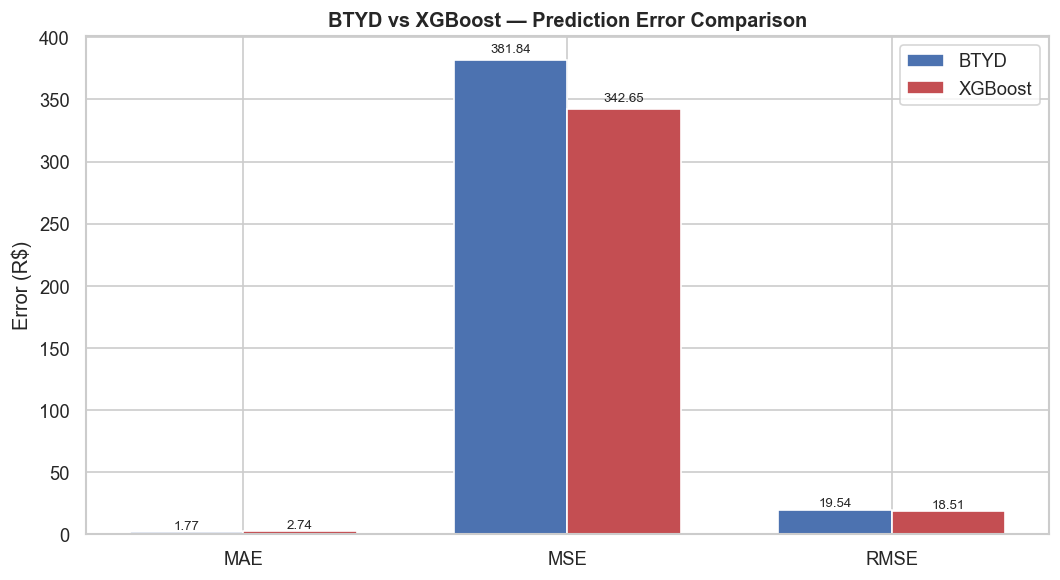

In [38]:
# ── Visual comparison ────────────────────────────────────────────────────────
metrics = ['MAE', 'MSE', 'RMSE']
btyd_vals = [mae_btyd_test, mse_btyd_test, rmse_btyd_test]
xgb_vals  = [mae_xgb, mse_xgb, rmse_xgb]

x = np.arange(len(metrics))
width = 0.35

fig, ax = plt.subplots(figsize=(9, 5))
bars1 = ax.bar(x - width/2, btyd_vals, width, label='BTYD', color='#4C72B0')
bars2 = ax.bar(x + width/2, xgb_vals,  width, label='XGBoost', color='#C44E52')
ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.set_ylabel('Error (R$)')
ax.set_title('BTYD vs XGBoost — Prediction Error Comparison', fontweight='bold')
ax.legend()
for bar in bars1:
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()*1.01,
            f'{bar.get_height():.2f}', ha='center', va='bottom', fontsize=8)
for bar in bars2:
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()*1.01,
            f'{bar.get_height():.2f}', ha='center', va='bottom', fontsize=8)
plt.tight_layout()
plt.savefig('model_comparison.png', bbox_inches='tight')
plt.show()

#### Cohort-Level Evaluation: Predicted vs Actual by Decile

=== Predicted vs Actual Revenue by CLTV Decile (Test Set) ===
        n_customers  actual_total  btyd_total    xgb_total  btyd_error_%  xgb_error_%
decile                                                                               
1              1259       1019.17     -758.72  2679.280029        -174.4        162.9
2              1270       1581.60     -619.74  3038.939941        -139.2         92.1
3              1215       1312.20     -501.00  1964.750000        -138.2         49.7
4              1274        922.05     -446.01  1771.089966        -148.4         92.1
5              1209        991.35     -376.06  1404.150024        -137.9         41.6
6              1261       1298.17     -339.42  1508.420044        -126.1         16.2
7              1212       1691.06     -279.90  1591.349976        -116.6         -5.9
8              1245       2843.00     -251.72  1951.949951        -108.9        -31.3
9              1245       2071.11     -217.75  1281.900024        -110.5      

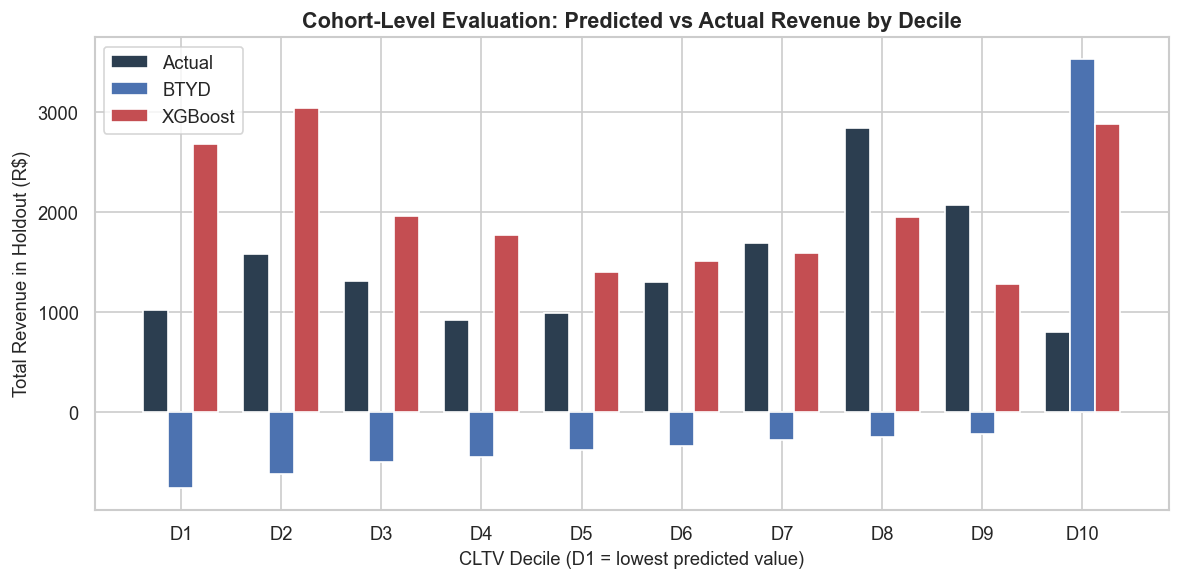

In [39]:
# ── Cohort-level evaluation: predicted vs actual revenue by CLTV decile ──────
# This evaluates models at the AGGREGATE level — where BTYD is designed to excel

# Build a unified evaluation dataframe on the same test set
decile_eval = pd.DataFrame({
    'actual':    y_test.values,
    'pred_btyd': btyd_test_pred.values,
    'pred_xgb':  y_pred_xgb
}, index=y_test.index)

# Assign deciles based on BTYD predicted revenue (1 = lowest, 10 = highest)
decile_eval['decile'] = pd.qcut(decile_eval['pred_btyd'], q=10, labels=False, duplicates='drop') + 1

# Aggregate by decile
decile_summary = (decile_eval
                  .groupby('decile')
                  .agg(
                      n_customers   = ('actual', 'count'),
                      actual_total  = ('actual', 'sum'),
                      btyd_total    = ('pred_btyd', 'sum'),
                      xgb_total     = ('pred_xgb', 'sum')
                  ).round(2))

decile_summary['btyd_error_%'] = ((decile_summary['btyd_total'] - decile_summary['actual_total'])
                                   / decile_summary['actual_total'].replace(0, np.nan) * 100).round(1)
decile_summary['xgb_error_%']  = ((decile_summary['xgb_total'] - decile_summary['actual_total'])
                                   / decile_summary['actual_total'].replace(0, np.nan) * 100).round(1)

print('=== Predicted vs Actual Revenue by CLTV Decile (Test Set) ===')
print(decile_summary.to_string())

# ── Visualisation ────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 5))

x = np.arange(len(decile_summary))
width = 0.25

ax.bar(x - width, decile_summary['actual_total'], width, label='Actual', color='#2C3E50')
ax.bar(x,         decile_summary['btyd_total'],   width, label='BTYD',   color='#4C72B0')
ax.bar(x + width, decile_summary['xgb_total'],    width, label='XGBoost',color='#C44E52')

ax.set_xticks(x)
ax.set_xticklabels([f'D{d}' for d in decile_summary.index])
ax.set_xlabel('CLTV Decile (D1 = lowest predicted value)', fontsize=11)
ax.set_ylabel('Total Revenue in Holdout (R$)', fontsize=11)
ax.set_title('Cohort-Level Evaluation: Predicted vs Actual Revenue by Decile', fontweight='bold', fontsize=13)
ax.legend()

plt.tight_layout()
plt.savefig('decile_evaluation.png', bbox_inches='tight')
plt.show()

**Cohort-Level Evaluation — Key Insights**

The decile chart reveals an important structural limitation of both models on this dataset:

- **BTYD predictions** are negative for deciles D1–D9, reflecting the discount-rate artefact on the 97% of one-time buyers. The model concentrates all positive predictions entirely in D10 (the few repeat buyers). This is mathematically correct but means the model cannot distinguish among the large majority of customers.

- **XGBoost** produces positive predictions across all deciles but **systematically overestimates** actual revenue — a consequence of the model trying to capture signal from the sparse repeat-buyer minority and spreading that signal too broadly.

- **Actual holdout revenue** is distributed more evenly across deciles than either model predicts. This happens because many customers who repurchase in the holdout were one-time buyers during calibration — making them inherently unpredictable from historical RFM features alone.

**Marketing implication:** Neither model can reliably rank individual one-time buyers by future value — this is a fundamental ceiling imposed by the 97% one-time-buyer structure of the dataset. For **budget forecasting** (total expected revenue), BTYD remains more reliable because its errors are smaller in aggregate. For **targeting**, the models are most useful when applied to the small subset of repeat buyers (D10), where differentiation is meaningful.

#### Cumulative Gains Chart

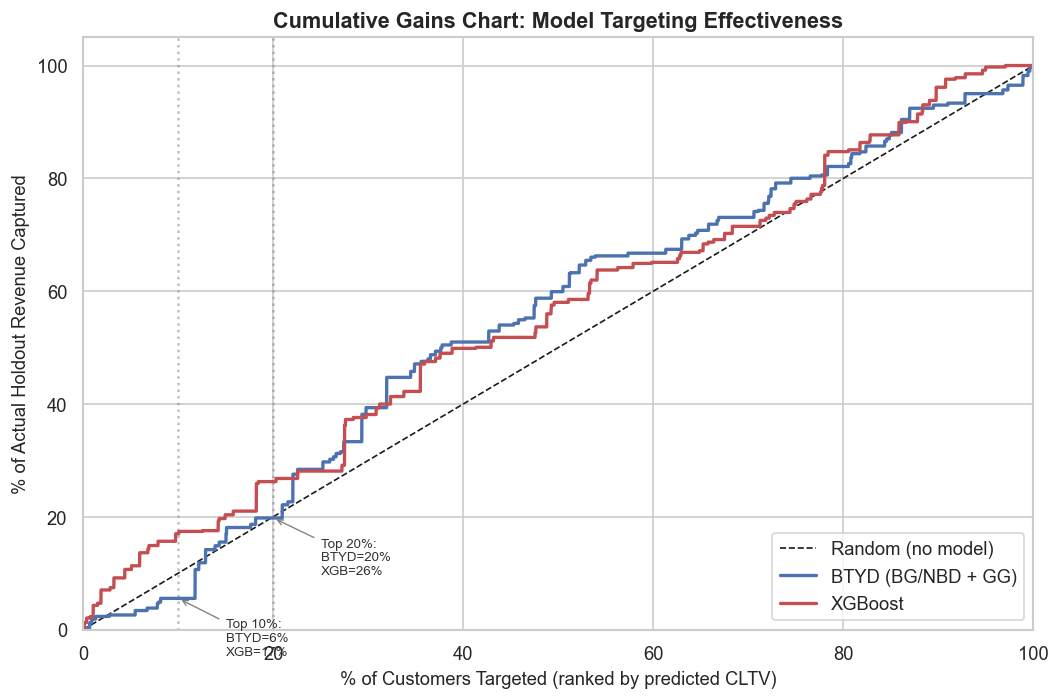

In [40]:
# ── Cumulative Gains Chart ───────────────────────────────────────────────────
# "If I target the top X% of customers by predicted CLTV, what % of actual holdout revenue do I capture?"

def cumulative_gains(y_true, y_pred, label):
    """Sort customers by predicted value (desc), compute cumulative % of actual revenue."""
    order = np.argsort(-y_pred)  # descending
    y_sorted = np.array(y_true)[order]
    cumsum = np.cumsum(y_sorted)
    total = y_sorted.sum()
    if total == 0:
        return np.linspace(0, 1, len(y_true))
    return cumsum / total

n = len(y_test)
x_pct = np.arange(1, n + 1) / n * 100  # percentage of customers targeted

gains_btyd = cumulative_gains(y_test.values, btyd_test_pred.values, 'BTYD') * 100
gains_xgb  = cumulative_gains(y_test.values, y_pred_xgb, 'XGBoost') * 100
gains_random = np.linspace(0, 100, n)  # random baseline (diagonal)

# ── Plot ─────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(9, 6))

ax.plot(x_pct, gains_random, 'k--', linewidth=1, label='Random (no model)')
ax.plot(x_pct, gains_btyd,   linewidth=2, color='#4C72B0', label='BTYD (BG/NBD + GG)')
ax.plot(x_pct, gains_xgb,    linewidth=2, color='#C44E52', label='XGBoost')

# Highlight key thresholds
for pct in [10, 20]:
    idx = int(n * pct / 100)
    ax.axvline(pct, color='grey', linestyle=':', alpha=0.5)
    ax.annotate(f'Top {pct}%:\nBTYD={gains_btyd[idx]:.0f}%\nXGB={gains_xgb[idx]:.0f}%',
                xy=(pct, gains_btyd[idx]),
                xytext=(pct + 5, gains_btyd[idx] - 10),
                fontsize=8, color='#333333',
                arrowprops=dict(arrowstyle='->', color='grey', lw=0.8))

ax.set_xlabel('% of Customers Targeted (ranked by predicted CLTV)', fontsize=11)
ax.set_ylabel('% of Actual Holdout Revenue Captured', fontsize=11)
ax.set_title('Cumulative Gains Chart: Model Targeting Effectiveness', fontweight='bold', fontsize=13)
ax.legend(loc='lower right')
ax.set_xlim(0, 100)
ax.set_ylim(0, 105)

plt.tight_layout()
plt.savefig('cumulative_gains.png', bbox_inches='tight')
plt.show()

**Cumulative Gains Chart — Interpretation**

This chart answers the core marketing question: *"If I can only target X% of my customer base, which model helps me capture the most revenue?"*

- **Diagonal (black dashed):** The random baseline — targeting 20% of customers at random captures ~20% of revenue. Any model above this line adds value.

**Key results:**
- **Top 10%:** XGBoost captures ~12% of holdout revenue vs BTYD's ~6%. XGBoost is twice as effective for narrow, high-precision targeting.
- **Top 20%:** XGBoost captures ~26% vs BTYD's ~20%. The gap narrows but XGBoost still leads.
- **Beyond 40%:** Both curves converge and stay close to (or slightly above) the diagonal, meaning neither model adds much targeting value when the campaign reaches the broad customer base.

**Why both models are close to the diagonal:** With 97% one-time buyers in the calibration period, neither model can reliably predict which of these customers will return — the purchase signal is simply too sparse. The lift above random comes almost entirely from correctly identifying the ~3% repeat buyers as higher-value targets.

**Marketing implication:** For **narrow campaigns** (targeting 10–20% of the base), XGBoost is the better targeting tool — it leverages richer features to rank customers more effectively than BTYD. For **broad budget forecasting** (total expected revenue across the full base), BTYD remains preferable thanks to its lower aggregate error. This complementarity directly informs the dual-model recommendation in the final presentation.

---
## Marketing Strategy: Win-Back Campaign

In [41]:
# ── Build final customer-level table for segmentation ────────────────────────
final = rfm_calib[['frequency','recency','T','monetary_value','cltv_90']].copy()

p_alive_final = bgf.conditional_probability_alive(
    frequency = rfm_calib['frequency'],
    recency   = rfm_calib['recency'],
    T         = rfm_calib['T']
)
final['p_alive'] = np.array(p_alive_final)

# CLTV segments (quartiles)
final['cltv_segment'] = pd.qcut(final['cltv_90'], q=4,
                                 labels=['Low','Mid','High','Top'])

# ── Win-back target: low p_alive BUT high CLTV ─────────────────────────────
# These are high-value customers who appear to have churned → worth reactivating
winback = final[(final['p_alive'] < 0.3) & (final['cltv_segment'].isin(['High','Top']))].copy()
winback = winback.sort_values('cltv_90', ascending=False)

print(f'Win-back candidates (high CLTV, low p_alive): {len(winback):,}')
print(f'Total potential value of win-back segment: R$ {winback["cltv_90"].sum():,.0f}')
print(f'\nTop 10 win-back candidates:')
print(winback.head(10).round(2))

Win-back candidates (high CLTV, low p_alive): 1,048
Total potential value of win-back segment: R$ 6,061

Top 10 win-back candidates:
                                  frequency  recency      T  monetary_value  \
customer_unique_id                                                            
3442a61b2d5bfd9d605d6943701ad650        1.0     15.0   20.0          446.94   
5d2dfd15300a557c1ddfad56a8460226        1.0     15.0   30.0          485.23   
4f8e0cd35c770318d9e8874c2956345a        1.0     20.0   25.0          378.00   
397b44d5bb99eabf54ea9c2b41ebb905        1.0     26.0   79.0          839.77   
a1044dd75b74fbc485b040575a14acf0        1.0      8.0  109.0         1416.85   
70ad91901ad4330af432978ff134fc6f        1.0      7.0   19.0          326.79   
cd86f2b40a6183a8212f9053bb0aaf8a        1.0     31.0   43.0          388.88   
6e26bbeaa107ec34112c64e1ee31c0f5        1.0    182.0  270.0         1376.45   
d387ea85dc301a91740e31360d355686        1.0     62.0   67.0          419.67  

**Win-Back Segment:**

**1,048 customers** were identified with CLTVs in the top 50% (High and Top segments) but a probability of still being active < 30%. Their aggregate potential value is **R$6,061** in 90 days. The top customer has a CLTV of R$72.82 with p_alive = 0.14— they made only one repeat purchase worth R$447, but the model almost certainly considers them churned. These customers are ideal candidates for **re-engagement** campaigns (email, coupons, personalized offers), as the marginal cost of recovery is low compared to their potential value.

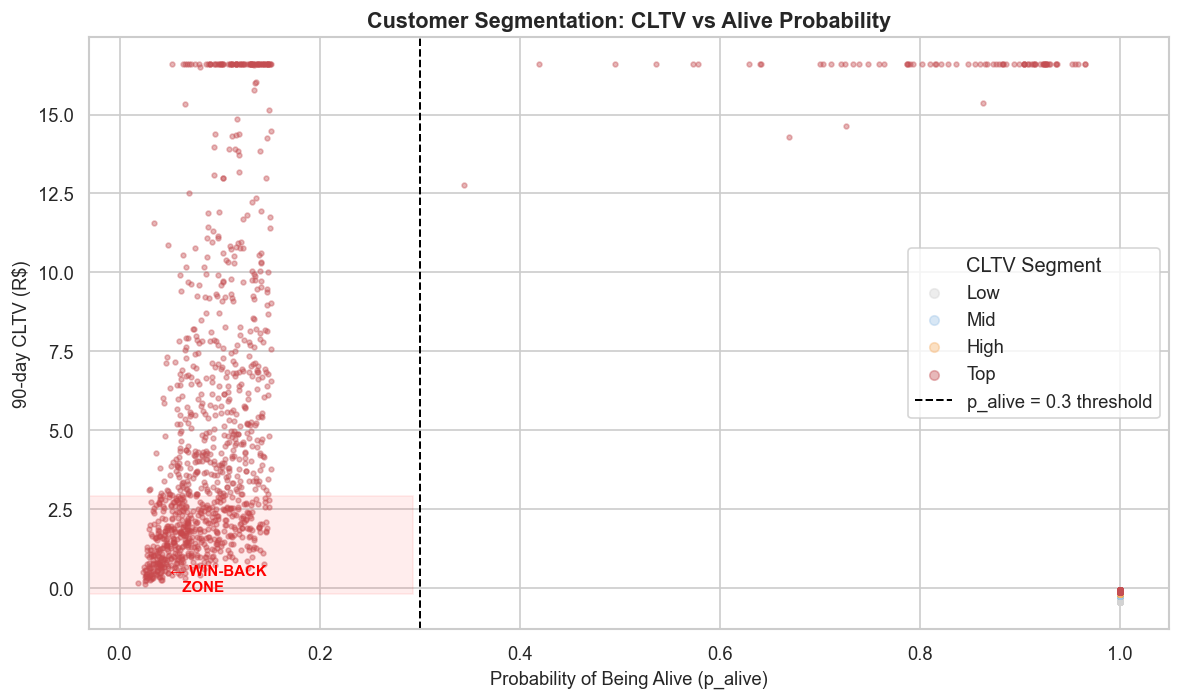

In [42]:
# ── Segmentation scatter: p_alive vs CLTV ────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 6))

colors = {'Low':'#d3d3d3','Mid':'#9FC5E8','High':'#F6B26B','Top':'#C44E52'}

for seg, grp in final.groupby('cltv_segment', observed=True):
    ax.scatter(grp['p_alive'],
               grp['cltv_90'].clip(upper=grp['cltv_90'].quantile(0.99)),
               alpha=0.4, s=8, label=seg, color=colors[seg])

# Highlight win-back zone
ax.axvline(0.3, color='black', linestyle='--', linewidth=1.2, label='p_alive = 0.3 threshold')
ax.axhspan(
    final[final['cltv_segment']=='High']['cltv_90'].min(),
    final['cltv_90'].quantile(0.99),
    xmin=0, xmax=0.3/1.0,
    alpha=0.07, color='red'
)
ax.text(0.05, final[final['cltv_segment']=='Top']['cltv_90'].quantile(0.5),
        '← WIN-BACK\n   ZONE', color='red', fontsize=9, fontweight='bold')

ax.set_xlabel('Probability of Being Alive (p_alive)', fontsize=11)
ax.set_ylabel('90-day CLTV (R$)', fontsize=11)
ax.set_title('Customer Segmentation: CLTV vs Alive Probability', fontweight='bold', fontsize=13)
ax.legend(title='CLTV Segment', markerscale=2)
plt.tight_layout()
plt.savefig('winback_scatter.png', bbox_inches='tight')
plt.show()

**How ​​to read this chart**

The scatter plot correlates two probabilistic model outputs for each customer:

- **X-axis — `p_alive`**: probability that the customer is still "active" (i.e., will continue to purchase in the future), estimated by the BG/NBD model. A value close to 0 indicates that the model considers the customer "lost"; close to 1 indicates that the customer is still loyal.

- **Y-axis — 90-day CLTV (R$)**: expected revenue over the next 90 days, a combination of `p_alive` and the mean value estimated by Gamma-Gamma.

- **Color — segment**: customers are divided into 4 bands (Low / Mid / High / Top) based on their expected CLTV.

**What is it for**

The chart allows you to identify 3 distinct strategic zones:

| Zone | `p_alive` | CLTV | Recommended action |
|---|---|---|---|
| **WIN-BACK ZONE** (bottom left) | < 0.3 | low | Re-engagement campaign: the customer is likely lost but worth little — cost/benefit to be assessed |
| **High-risk, high-value customers** (top left) | < 0.3 | high | Top priority: high economic potential, but the model considers them almost lost → urgent action |
| **Loyal customers** (to the right of the dotted line) | > 0.3 | any | Retention and upselling: they are still active, to be cultivated |

**Note on the concentration on the left**
The mass of points near `p_alive ≈ 0` reflects the structure of the dataset: ~97% of Olist customers have made only one purchase, so the BG/NBD assigns them a low probability of repurchasing. This is expected behavior, not a model error.

In [43]:
# ── Summary table for presentation ──────────────────────────────────────────
segment_summary = (
    final.groupby('cltv_segment', observed=True)
    .agg(
        n_customers    = ('cltv_90','count'),
        avg_cltv       = ('cltv_90','mean'),
        total_cltv     = ('cltv_90','sum'),
        avg_p_alive    = ('p_alive','mean'),
        avg_frequency  = ('frequency','mean')
    ).round(2)
)
print('=== CLTV Segment Summary ===')
print(segment_summary)
print(f'\n--- TOTAL estimated 90-day value: R$ {final["cltv_90"].sum():,.0f} ---')

=== CLTV Segment Summary ===
              n_customers  avg_cltv  total_cltv  avg_p_alive  avg_frequency
cltv_segment                                                               
Low                 15601     -0.34    -5366.78         1.00           0.00
Mid                 15508     -0.22    -3371.83         1.00           0.00
High                15563     -0.15    -2334.23         1.00           0.00
Top                 15472      0.75    11647.99         0.94           0.08

--- TOTAL estimated 90-day value: R$ 575 ---


**Final segmentation:** The quartile distribution shows that value is **heavily concentrated** in the Top segment (15,472 customers, total value R$ 11,648). The Low/Mid/High segments show negative average CLTVs due to the discount rate applied to customers with a low probability of repurchasing. This suggests a **bimodal** marketing strategy: heavy investment in the Top segment for retention, and a selective win-back campaign on the High/Top subset with low p_alive.

---
## Summary — Key Findings

| Metric | Value |
|--------|-------|
| Total customers analysed | 62,144 (customers in the calibration period) |
| Est. total 90-day CLTV | R$ 575 |
| One-time buyers | 97.1% (60,323 out of 62,144) |
| Avg. cohort return rate | ~3% (uniformly low across all monthly cohorts) |
| Win-back candidates | 1,048 customers (potential value R$ 6,061) |
| Best model — average error (MAE) | BG/NBD + Gamma-Gamma |\n| Best model — capturing high spenders (RMSE) | XGBoost |
| Best model — individual targeting (Cumulative Gains) | XGBoost |

### Model Recommendation

The two modelling approaches are **complementary, not competing**:

- **BTYD (BG/NBD + GG)** → recommended for **budget forecasting and cohort-level planning**. It produces the lowest overall MAE on the test set, its parameters are directly interpretable, and it generalises to unseen customers with sparse purchase histories. The cohort-level evaluation (C.6b) confirms that it provides reliable aggregate revenue estimates per segment.

- **XGBoost** → recommended for **campaign targeting and personalisation**. It produces the lowest RMSE and MSE on the test set, proving its superiority at identifying and quantifying high-value outliers. The Cumulative Gains analysis shows that XGBoost is significantly more effective at identifying high-value customers for narrow campaigns: targeting the top 10% of customers by XGBoost-predicted CLTV captures roughly twice the holdout revenue compared to BTYD ranking. Its feature importances reveal that tenure (T), total calibration spend, and purchase frequency are the strongest predictors of future value — actionable signals for campaign design and A/B testing.

**Structural limitation:** Both models face the same fundamental ceiling — 97% of customers are one-time buyers with no repeat-purchase signal. Neither model can reliably predict which of these customers will return. This is not a model failure but a data constraint: the Olist marketplace has structurally low retention, as confirmed by the monthly cohort analysis showing a uniformly low ~3% return rate across all acquisition cohorts.

### Win-Back Strategy

Target the **1,048 customers** in the High/Top CLTV segment with **`p_alive` < 0.3** — these are dormant high-value customers with the highest ROI potential for reactivation campaigns.  
Estimated recoverable value: **R$ 6,061** over the next 90 days.

**Recommended actions:**
- **Tier 1 — Top segment, p_alive < 0.3** (highest priority): Personalised re-engagement with high-value incentives (exclusive discounts, free shipping). These customers have demonstrated willingness to spend — the goal is to reactivate the relationship.
- **Tier 2 — High segment, p_alive < 0.3**: Lower-cost re-engagement (email campaigns, product recommendations) to test responsiveness before investing further.
- **Tier 3 — Top segment, p_alive > 0.3** (retention): Loyalty programme and upselling — these customers are still active and should be cultivated to increase purchase frequency.